# **Теория №3. Основные методы OpenCV (Часть №2). Базовые операции**

## **1. Создание растров и геометрических примитивов в OpenCV**

Растровое изображение представляет собой двумерный массив пикселей, где каждый пиксель имеет определенное значение цвета. В OpenCV изображения хранятся в виде массивов NumPy, что обеспечивает эффективное использование оперативной памяти и высокую скорость вычислений.

### **1.1. Создание цветного изображения**



#### Пример №1. Черный квадрат


Чтобы создать однотонное цветное изображение (например, состоящее полностью из черного цвета), можно использовать функцию `np.zeros()` из библиотеки NumPy:

In [ ]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

# Создаем черный квадрат размером 512x512 пикселей с 3 цветовыми каналами (BGR)
image = np.zeros((512, 512, 3), dtype=np.uint8)

**Пояснения:**

- `np.zeros((512, 512, 3), dtype=np.uint8)` создаёт массив заданной формы, заполненный нулями.
  - `(512, 512, 3)` — размерность массива: высота, ширина и количество цветовых каналов.
  - `dtype=np.uint8` — тип данных массива; беззнаковое 8-битное целое число с диапазоном значений от 0 до 255.

#### Отображение цветного изображения



При отображении изображения с помощью `matplotlib` необходимо учитывать разницу в цветовых форматах:

- OpenCV использует формат BGR (Blue, Green, Red).
- Matplotlib ожидает формат RGB (Red, Green, Blue).

Чтобы корректно отобраить изображение, нужно преобраовать цветовое пространство:

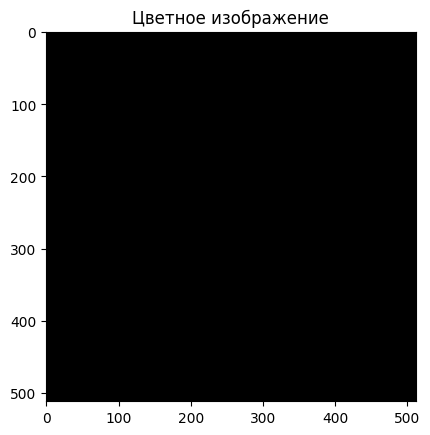

In [ ]:
# Преобрауем изображение из BGR в RGB
image_rgb = cv.cvtColor(image, cv.COLOR_BGR2RGB)

# Отображаем изображение
plt.imshow(image_rgb)
plt.title("Цветное изображение")
plt.show()

#### Пример №2. Синий квадрат

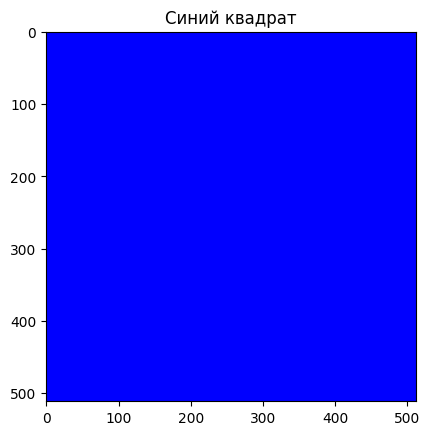

In [ ]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

# Создаем изображение 512x512 пикселей с 3 каналами (BGR), заполненное нулями (черный цвет)
image = np.zeros((512, 512, 3), dtype=np.uint8)

# Заполняем все пиксели синим цветом
image[:] = (255, 0, 0)  # В OpenCV формат цвета BGR, поэтому порядок (Blue, Green, Red)

# Преобрауем изображение из BGR в RGB для корректного отображения в Matplotlib
image_rgb = cv.cvtColor(image, cv.COLOR_BGR2RGB)

# Отображаем изображение
plt.imshow(image_rgb)
plt.title("Синий квадрат")
plt.show()

#### Пример №3. Создание градиента цвета

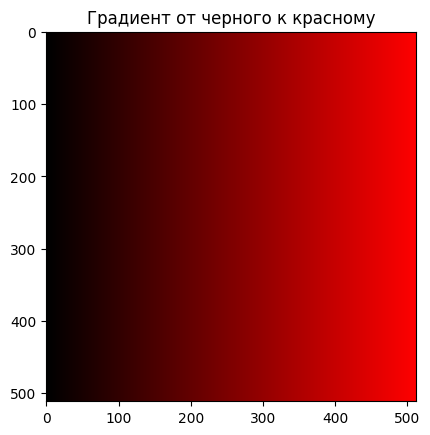

In [ ]:
# Создаем пустой массив
image = np.zeros((512, 512, 3), dtype=np.uint8)

# Создаем горизонтальный градиент от черного к красному
for x in range(512):
    color_intensity = int((x / 512) * 255)
    image[:, x] = (0, 0, color_intensity)  # Изменяем интенсивность красного канала

# Преобразуем и отображаем изображение
image_rgb = cv.cvtColor(image, cv.COLOR_BGR2RGB)
plt.imshow(image_rgb)
plt.title("Градиент от черного к красному")
plt.show()

**Как формируется градиент в цикле?**

1. **Итерация по столбцам изображения:**
   
   Цикл проходит по каждому столбцу изображения по горизонтальной оси от левого края к правому. Поскольку ширина изображения составляет 512 пикселей, значения переменной `x` будут изменяться от 0 до 511.

2. **Вычисление интенсивности красного цвета:**
   
   Для каждого столбца `x` вычисляется значение `color_intensity`, которое определяет степень насыщенности красного цвета в данном столбце. Расчет производится следующим образом:

   - **Нормализация позиции:** Делим текущий номер столбца `x` на общую ширину изображения 512, получая значение в диапазоне от 0 до 1.
   - **Масштабирование интенсивности:** Умножаем полученное значение на 255 (максимальное значение интенсивности цвета для 8-битного изображения), получая значение интенсивности в диапазоне от 0 до 255.
   - **Преобразование в целое число:** Приводим вычисленную интенсивность к целочисленному значению, чтобы она могла быть использована в цветовом канале изображения.

   Таким образом, по мере продвижения от левого края к правому, интенсивность красного цвета плавно увеличивается от 0 до 255.

3. **Присвоение цвета пикселям столбца:**
   
   - Для текущего столбца `x` все пиксели по вертикали (все строки) устанавливаются в цвет с определенной интенсивностью красного канала.
   - Значения синего и зеленого каналов устанавливаются в 0, чтобы исключить их влияние и оставить только красный цвет.
   - Это означает, что каждый столбец изображения будет иметь свой уникальный оттенок красного, зависящий от его положения по горизонтали.

4. **Формирование градиента:**
   
   - **Левая сторона изображения:** Когда `x` близко к 0, интенсивность красного цвета минимальна (близка к 0), и цвет пикселей в этом столбце будет черным или почти черным.
   - **Правая сторона изображения:** Когда `x` близко к 511, интенсивность красного цвета максимальна (близка к 255), и цвет пикселей будет ярко-красным.
   - **Промежуточные значения:** Между левым и правым краями интенсивность красного цвета постепенно увеличивается, создавая плавный переход от темного к светлому оттенку красного.

В результате выполнения этого цикла на изображении формируется горизонтальный градиент, изменяющийся от черного цвета слева к ярко-красному справа. Каждый столбец изображения отражает определенную интенсивность красного цвета, создавая визуальный эффект плавного перехода по всей ширине изображения. Такой подход позволяет наглядно продемонстрировать изменение интенсивности цвета в зависимости от положения на изображении.

### **1.2. Создание черно-белого изображения**

Для создания черно-белого (градаций серого) изображения достаточно двумерного массива:

#### Пример №1. Черный квадрат

In [ ]:
# Создаем черное черно-белое изображение размером 512x512 пикселей
image_bw = np.zeros((512, 512), dtype=np.uint8)

#### Отображение черно-белого изображения

При отображении черно-белого изображения с помощью `matplotlib` следует указать цветовую карту `gray`:

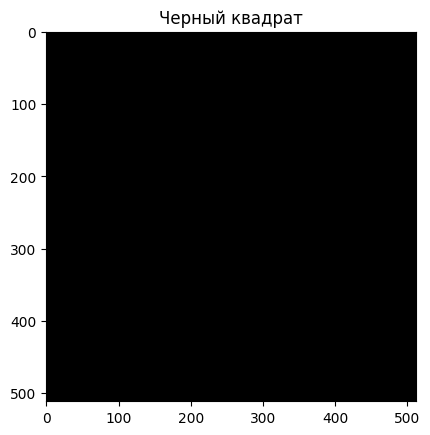

In [ ]:
# Отображаем черно-белое изображение
plt.imshow(image_bw, cmap='gray')
plt.title("Черный квадрат")
plt.show()

**Примечание:** Преобразование цветового пространства с помощью `cv.cvtColor()` для одномерных (черно-белых) изображений не требуется.

#### Пример №2. Черно-белое изображение с градацией

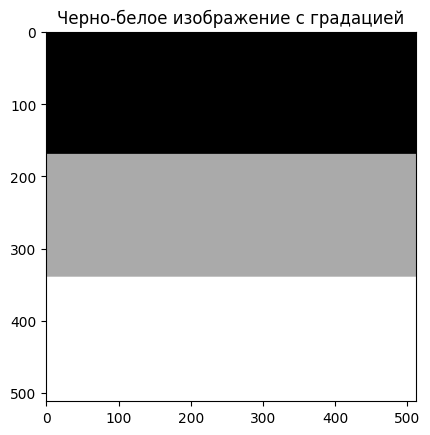

In [ ]:
# Создаем черно-белое изображение (полностью черное)
image_bw = np.zeros((512, 512), dtype=np.uint8)

# Заполняем среднюю треть изображения серым цветом
image_bw[170:340, :] = 170  # Интенсивность 170 дает серый цвет

# Заполняем нижнюю треть изображения белым цветом
image_bw[340:512, :] = 255  # Интенсивность 255 дает белый цвет

# Отображаем изображение в градациях серого
plt.imshow(image_bw, cmap='gray')
plt.title("Черно-белое изображение с градацией")
plt.show()

### **1.3. Создание линий**

> Линии - это базовые элементы в компьютерной графике, позволяющие создавать простые формы и контуры. В OpenCV линии рисуются с помощью функции `cv.line()`, которая соединяет две точки на изображении. Эта функция позволяет задать цвет, толщину и тип линии, что делает ее гибким инструментом для создания различных визуальных эффектов.

**Функция `cv.line()` принимает следующие аргументы:**

1. `image`: Изображение, на котором вы хотите нарисовать линию. Это должно быть изображение, на котором уже вызван `cv.imread()` или создано с помощью `numpy`.
2. `point1`: Кортеж из двух значений `(x1, y1)`, который представляет начальную точку линии на изображении.
3. `point2`: Кортеж из двух значений `(x2, y2)`, который представляет конечную точку линии на изображении.
4. `color`: Цвет линии. Это кортеж из трех значений `(B, G, R)`, представляющих цвет в пространстве BGR (синий, зеленый, красный).
5. `thickness`: Толщина линии в пикселях. Если не указано, по умолчанию используется толщина = 1.



In [ ]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

# Создаем черный квадрат размером 512x512 пикселей с 3 цветовыми каналами (BGR)
image = np.zeros((512, 512, 3), dtype=np.uint8) # Наш "холст" для рисования

Координаты в OpenCV указываются в формате (x, y), где x – это горизонтальная ось слева направо, а y – это вертикальная ось сверху вниз.

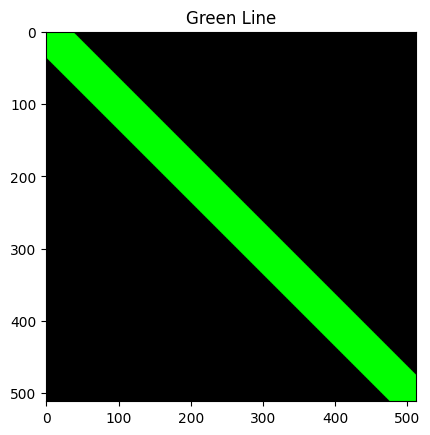

In [ ]:
# Создаем кортеж point1, который представляет собой координаты начальной точки линии
point1 = (0, 0)
# Создаем кортеж point2, который представляет собой координаты конечной точки линии
point2 = (511, 511)
# Определяем цвет для линии в формате BGR (но зеленый цвет задан некорректно, так как макс. значение должно быть 255, не 256)
color = (0, 256, 0)  # Зеленый
# Устанавливаем толщину линии равной 50 пикселям
thickness = 50

# Здесь происходит вызов функции line из библиотеки OpenCV,
# которая рисует линию на изображении `image` от `point1` до `point2`,
# зеленым цветом (`color`) и с толщиной в 50 пикселей (`thickness`).
cv.line(image, point1, point2, color, thickness)


plt.imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB))
plt.title("Green Line")
plt.show()

### **1.4. Создание прямоугольников**

> Прямоугольники широко используются в компьютерном зрении для выделения областей интереса на изображениях. Функция `cv.rectangle()` в OpenCV позволяет легко рисовать прямоугольники, задавая координаты противоположных углов. Это особенно полезно при работе с алгоритмами обнаружения объектов, где прямоугольники часто используются для обозначения найденных объектов.

Метод `cv.rectangle()` является функцией в библиотеке OpenCV для Python. Он используется для рисования прямоугольника на изображении.

**Параметры функции cv.rectangle():**

1. `img`: Изображение, на котором вы хотите нарисовать прямоугольник. Это должно быть изображение, полученное с помощью OpenCV, например, с помощью `cv.imread()` или как результат обработки.

2. `pt1`: Кортеж, указывающий верхний левый угол прямоугольника. В форме (x, y).

3. `pt2`: Кортеж, указывающий нижний правый угол прямоугольника. Также в форме (x, y).

4. `color`: Цвет прямоугольника. Это обычно кортеж из трех значений, которые представляют BGR (Blue, Green, Red) значение цвета. Например, синий цвет будет (255, 0, 0).

5. `thickness`: Толщина линий прямоугольника. Значение `-1` заливает весь прямоугольник цветом. По умолчанию это 1 пиксель.

6. `lineType`: Тип линии прямоугольника. Это может быть `cv.LINE_8`, `cv.LINE_4`, или `cv.LINE_AA`, что определяет алгоритм рисования линии.

7. `shift`: Количество десятичных бит для точности координат. Это позволяет более точно задать координаты точек.

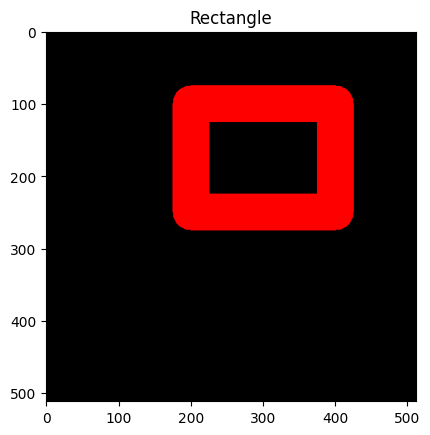

In [ ]:
# Создаем изображение размером 512x512 пикселей, 3 канала (RGB), все пиксели черные (0).
image = np.zeros((512, 512, 3), np.uint8) # np.uint8 - это тип данных для пикселей, который обозначает 8-битный целый тип от 0 до 255.

# Для объекта image вызываем функцию rectangle из библиотеки OpenCV.
# Рисуем прямоугольник:
# начальная точка (200, 100), конечная точка (400, 250),
# цвет прямоугольника (0, 0, 256),
# толщина линий прямоугольника - 50 пикселей.
cv.rectangle(image, (200, 100), (400, 250), (0, 0, 256), 50)


plt.imshow(cv.cvtColor(image, cv.COLOR_RGB2BGR))
plt.title("Rectangle")
plt.show()

### **1.5. Создание круга и полигона**

>Круги и полигоны позволяют создавать более сложные геометрические формы на изображениях.
>
>- Круги, рисуемые с помощью `cv.circle()`, часто используются для выделения точек интереса или создания круговых меток.
>
>- Полигоны, создаваемые функцией `cv.polylines()`, предоставляют возможность рисовать произвольные многоугольные формы, что полезно при сегментации изображений или создании масок сложной формы.
>
>Эти примитивы расширяют возможности визуализации данных и результатов обработки изображений в различных задачах компьютерного зрения.

#### **Метод `cv.polylines()`**





`cv.polylines(image, pts, isClosed, color, thickness, lineType, shift)`

**Параметры:**
- `image`: Изображение, на котором будут рисоваться линии. Это должно быть изображение, где операция будет выполняться непосредственно.
- `pts`: Массив точек, которые определяют полилинии. Эти точки должны быть в формате NumPy и иметь целочисленный тип данных.
- `isClosed`: Булево значение, которое указывает, следует ли закрыть контур полилинии (соединить последнюю точку с первой). `True` для закрытой полилинии, `False` для открытой.
- `color`: Цвет полилинии в формате BGR (синий, зеленый, красный) или иногда может быть в градации серого для одноканальных изображений.
- `thickness`: Толщина линии. Если она отрицательна, например `-1`, то полилиния рисуется и заливается заданным цветом.
- `lineType`: Тип линии. Это может быть `8` (или `cv.LINE_8`), `4` (или `cv.LINE_4`) или `cv.LINE_AA`, что соответствует сглаживанию.
- `shift`: Параметр, который обозначает количество десятичных знаков после запятой для точек.

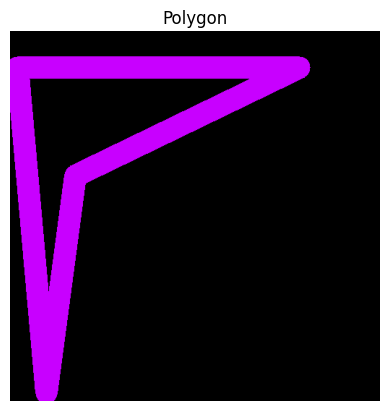

In [ ]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

# Создаем черное изображение размером 512x512 пикселей
image = np.zeros((512, 512, 3), np.uint8)

# Определяем массив точек для вершин полигона
points = np.array([[10, 50], [400, 50], [90, 200], [50, 500]], np.int32)

# Изменяем форму массива, чтобы он подходил для функции cv.polylines
points = points.reshape((-1, 1, 2))

# Рисуем полигон на изображении с помощью функции cv.polylines()
# Параметры:
# - image: изображение, на котором рисуем
# - [points]: массив точек полигона
# - True: замкнуть полигон
# - (255, 0, 200): цвет линии в формате BGR
# - 30: толщина линии
cv.polylines(image, [points], True, (255, 0, 200), 30)

# Отображаем изображение
plt.imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB))
plt.title("Polygon")
plt.axis('off')
plt.show()

#### **Метод `cv.circle()`**

`cv.circle(image, center, radius, color, thickness, lineType, shift)`

**Параметры:**
- `image`: Изображение, на котором будет рисоваться круг.
- `center`: Координаты центра круга в виде кортежа `(x, y)`.
- `radius`: Радиус круга.
- `color`: Цвет круга в формате BGR или оттенках серого для одноканальных изображений.
- `thickness`: Толщина обводки круга. При задании значения `-1` круг будет полностью закрашен данным цветом.
- `lineType`: Аналогично `cv.polylines()`, это тип линии для рисования краев круга.
- `shift`: Так же, как и в `cv.polylines()`, этот параметр позволяет управлять позиционированием центра с subpixel точностью.

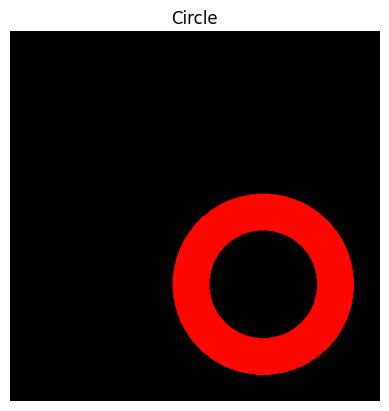

In [ ]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

# Создаем черное изображение размером 512x512 пикселей
image = np.zeros((512, 512, 3), np.uint8)

# Рисуем круг на изображении с помощью функции cv.circle()
# Параметры:
# - image: изображение, на котором рисуем
# - (350, 350): координаты центра круга
# - 100: раиус круга
# - (1, 7, 255): цвет круга в формате BGR (почти красный цвет)
# - 50: толщина контура (если указать -1, круг будет заполнен)
cv.circle(image, (350, 350), 100, (1, 7, 255), 50)

# Отображаем изображение
plt.imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB))
plt.title("Circle")
plt.axis('off')
plt.show()

### **1.6. Добавление текста**

> Добавление текста к изображениям — важная функция в обработке изображений и компьютерном зрении.В OpenCV для этой цели используется метод `cv.putText()`. Этот метод позволяет наносить текст на изображение с различными параметрами, такими как шрифт, размер, цвет и положение.




Вот основные параметры метода `cv.putText()` в Python:

```python
cv.putText(img, text, org, fontFace, fontScale, color[, thickness[, lineType[, bottomLeftOrigin]]])
```

Каждый из параметров имеет своё назначение:

1. `img`: Изображение, на котором будет отображаться текст. Это должен быть массив NumPy, который обычно загружается или создаётся с использованием OpenCV.

2. `text`: Строка текста, которую нужно отобразить на изображении.

3. `org`: Координата начальной точки текста на изображении. Это кортеж, содержащий позицию по оси X и Y (например, `(50, 100)`), где (0, 0) — это верхний левый угол изображения.

4. `fontFace`: Шрифт текста. OpenCV предоставляет несколько предустановленных шрифтов, таких как `cv.FONT_HERSHEY_SIMPLEX`, `cv.FONT_HERSHEY_PLAIN` и т.д. С кириллицей корректно работает шрифт cv.`FONT_HERSHEY_COMPLEX`

5. `fontScale`: Масштаб шрифта, который определяет размер текста. Значение типа float (например, `1.0`, `0.5`).

6. `color`: Цвет текста. Это обычно кортеж из трёх элементов, представляющих цвета в формате BGR (синий, зелёный, красный), например, `(255, 0, 0)` для синего цвета.

7. `thickness` (необязательно): Толщина линий, из которых состоит текст. Целое число.

8. `lineType` (необязательно): Тип линии текста. Может быть `cv.LINE_8`, `cv.LINE_4`, `cv.LINE_AA`, где `cv.LINE_AA` даёт сглаженный текст с использованием антиалиасинга.

9. `bottomLeftOrigin` (необязательно): Логическое значение, указывающее, должно ли начало координат быть в нижнем левом углу (True) или в верхнем левом (False, по умолчанию).

#### Пример №1. Добавление текста, состоящего из кириллических символов

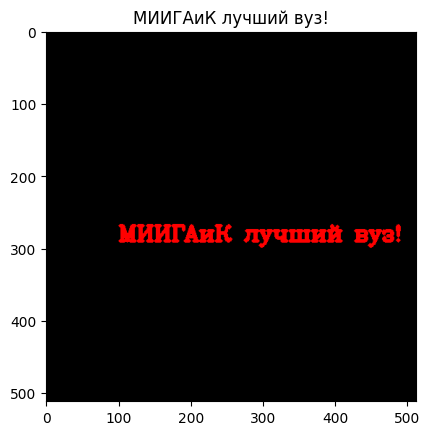

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

image = np.zeros((512, 512, 3), np.uint8)

# Добавляем текст на изображение
cv.putText(image,                        # Изображение, на которое наносится текст
           "МИИГАиК лучший вуз!",        # Текст для отображения
           (100, 290),                   # Координаты левого нижнего угла текста (x, y)
           cv.FONT_HERSHEY_COMPLEX,      # Шрифт (поддерживает кириллицу)
           1,                            # Масштаб шрифта
           (0, 0, 256),                  # Цвет текста в формате BGR (красный)
           3)                            # Толщина линий текста

plt.imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB))
plt.title("МИИГАиК лучший вуз!")
plt.show()

#### Пример №2. Добавления текста в разных стилях

> Примечание: Все представленные стили, кроме `FONT_HERSHEY_COMPLEX`, не поддерживают кириллические символы

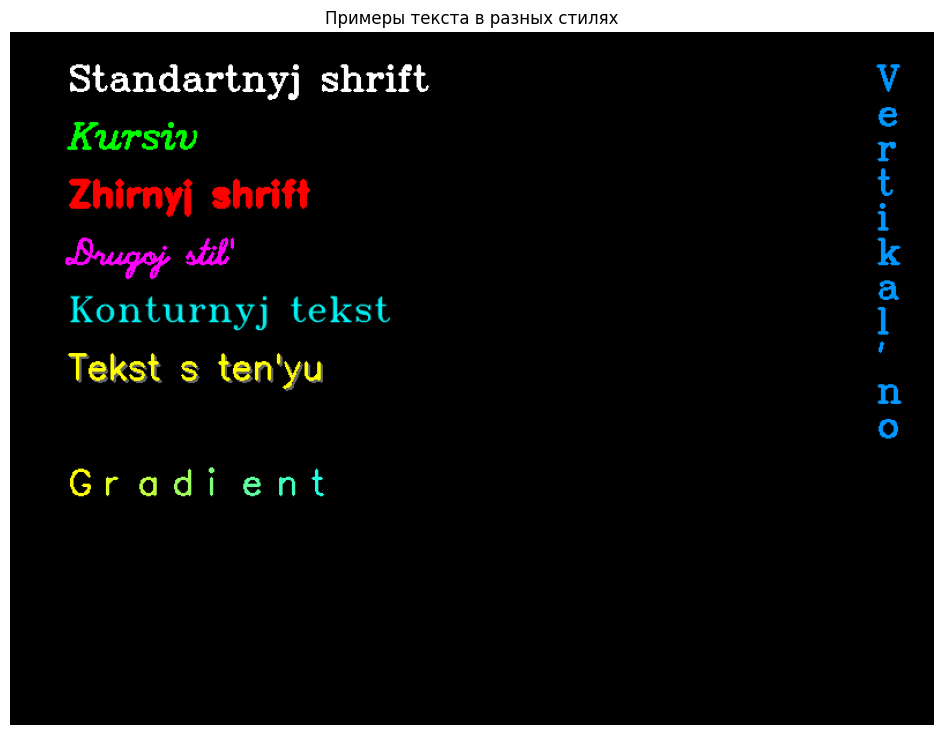

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# Создаем черное изображение
image = np.zeros((600, 800, 3), np.uint8)

# 1. Стандартный шрифт
cv.putText(image, "Standartnyj shrift", (50, 50), cv.FONT_HERSHEY_COMPLEX, 1, (255, 255, 255), 2)

# 2. Курсив
cv.putText(image, "Kursiv", (50, 100), cv.FONT_HERSHEY_COMPLEX | cv.FONT_ITALIC, 1, (0, 255, 0), 2)

# 3. Жирный шрифт
cv.putText(image, "Zhirnyj shrift", (50, 150), cv.FONT_HERSHEY_DUPLEX, 1, (0, 0, 255), 3)

# 4. Другой стиль
cv.putText(image, "Drugoj stil'", (50, 200), cv.FONT_HERSHEY_SCRIPT_SIMPLEX, 1, (255, 0, 255), 2)

# 5. Контурный текст
cv.putText(image, "Konturnyj tekst", (50, 250), cv.FONT_HERSHEY_TRIPLEX, 1, (255, 255, 0), 1, cv.LINE_AA)

# 6. Текст с тенью
shadow_offset = 2
cv.putText(image, "Tekst s ten'yu", (50+shadow_offset, 300+shadow_offset), cv.FONT_HERSHEY_SIMPLEX, 1, (100, 100, 100), 2)
cv.putText(image, "Tekst s ten'yu", (50, 300), cv.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 255), 2)

# 7. Вертикальный текст
for i, char in enumerate("Vertikal'no"):
    cv.putText(image, char, (750, 50 + i*30), cv.FONT_HERSHEY_COMPLEX, 1, (255, 150, 0), 2)

# 8. Градиентный текст
text = "Gradient"
for i, char in enumerate(text):
    color = (int(255 * i / len(text)), 255, 255 - int(255 * i / len(text)))
    cv.putText(image, char, (50 + i*30, 400), cv.FONT_HERSHEY_SIMPLEX, 1, color, 2)

# Отображаем результат
plt.figure(figsize=(12, 9))
plt.imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB))
plt.title("Примеры текста в разных стилях")
plt.axis('off')
plt.show()


## **2. Основные геометрические преобразования**

Загружаем исходное изображение

In [ ]:
# Ссылка на файл для скачивания
url = r'https://2spalnika.ru/wp-content/uploads/2022/12/zhivotniy-mir-hibin-800x600.jpg'

# Скачиваем файл с помощью wget
!wget -O arctic_fox.jpg '{url}'

--2024-10-16 18:20:45--  https://2spalnika.ru/wp-content/uploads/2022/12/zhivotniy-mir-hibin-800x600.jpg
Resolving 2spalnika.ru (2spalnika.ru)... 87.236.16.233
Connecting to 2spalnika.ru (2spalnika.ru)|87.236.16.233|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 105772 (103K) [image/jpeg]
Saving to: ‘arctic_fox.jpg’

arctic_fox.jpg      100%[===================>] 103.29K   294KB/s    in 0.4s    

2024-10-16 18:20:46 (294 KB/s) - ‘arctic_fox.jpg’ saved [105772/105772]



#### Вспомогательные функции

In [ ]:
# Функция для отображения изображений
def plot_images(images, titles):
    n = len(images)
    plt.figure(figsize=(15, 5))
    for i in range(n):
        plt.subplot(1, n, i + 1)
        if images[i].ndim == 2:
            plt.imshow(images[i], cmap='gray')
        else:
            plt.imshow(cv2.cvtColor(images[i], cv2.COLOR_BGR2RGB))
        plt.title(titles[i])
        plt.axis('off')
    plt.show()

# Вспомогательная функция для получения значения пикселя
def get_pixel(img, x, y):
    return img[int(y)][int(x)]

# Функция для вывода значений пикселей
def print_pixel_values(img, title):
    print(f"\n{title}:")
    print(img)

#### Формирование тестового изображения

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Исходное изображение 4x4
original = np.array([
    [50, 100, 150, 200],
    [75, 125, 175, 225],
    [100, 150, 200, 250],
    [125, 175, 225, 255]
])

### **2.1. Поворот изображений (метод `cv2.rotate()`)**



Метод `cv2.rotate()` позволяет поворачивать изображение на фиксированные углы: 90°, 180°, 270°. Он имеет следующий синтаксис:

```python
rotated_image = cv2.rotate(src, rotateCode)
```

**Параметры метода:**

- `src` — исходное изображение, которое необходимо повернуть.
- `rotateCode` — код поворота, определяющий угол и направление поворота. Возможные значения:
  - `cv2.ROTATE_90_CLOCKWISE` — поворот на 90° по часовой стрелке.
  - `cv2.ROTATE_180` — поворот на 180°.
  - `cv2.ROTATE_90_COUNTERCLOCKWISE` — поворот на 90° против часовой стрелки.

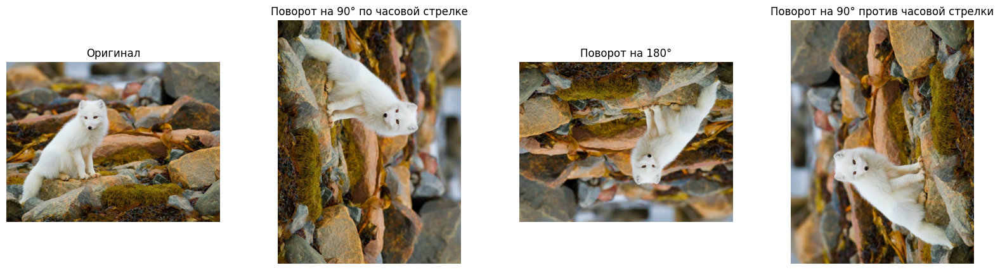

In [ ]:
import cv2
import matplotlib.pyplot as plt

# Считывание изображения
image = cv2.imread('/content/arctic_fox.jpg')

# Поворот на 90° по часовой стрелке
rotated_90_clockwise = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)

# Поворот на 180°
rotated_180 = cv2.rotate(image, cv2.ROTATE_180)

# Поворот на 90° против часовой стрелки
rotated_90_counterclockwise = cv2.rotate(image, cv2.ROTATE_90_COUNTERCLOCKWISE)

# Отображение изображений в один ряд
plt.figure(figsize=(20, 5))

plt.subplot(1, 4, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title('Оригинал')
plt.axis('off')

plt.subplot(1, 4, 2)
plt.imshow(cv2.cvtColor(rotated_90_clockwise, cv2.COLOR_BGR2RGB))
plt.title('Поворот на 90° по часовой стрелке')
plt.axis('off')

plt.subplot(1, 4, 3)
plt.imshow(cv2.cvtColor(rotated_180, cv2.COLOR_BGR2RGB))
plt.title('Поворот на 180°')
plt.axis('off')

plt.subplot(1, 4, 4)
plt.imshow(cv2.cvtColor(rotated_90_counterclockwise, cv2.COLOR_BGR2RGB))
plt.title('Поворот на 90° против часовой стрелки')
plt.axis('off')

plt.show()

#### **Математический аппарат**

При повороте изображения на кратные 90° можно воспользоваться простыми преобразованиями индексов элементов массивов (пикселей) без использования сложных матричных операций. Рассмотрим, как изменяются координаты пикселей при повороте изображения.

Пусть дано исходное изображение `src` размером $H \times W$, где:
- $H$ — высота (количество строк),
- $W$ — ширина (количество столбцов).

Каждый пиксель исходного изображения обозначается как $src_{i,j}$, где:
- $i \in [0, H - 1]$ — индекс строки,
- $j \in [0, W - 1]$ — индекс столбца.
---
#### **1. Поворот на 90° по часовой стрелке**

При повороте изображения на 90° по часовой стрелке новое изображение `dst` будет иметь размер $W \times H$ (ширина и высота меняются местами).

**Формула преобразования координат:**

$$
dst_{i', j'} = src_{H - j - 1, i}
$$

- $i' = i$
- $j' = j$

Однако в реализации мы обычно изменяем индексы следующим образом:

$$
dst_{j, H - i - 1} = src_{i, j}
$$

То есть:
- По строкам (`i'`): $i' = j$
- По столбцам (`j'`): $j' = H - i - 1$
---

#### **2. Поворот на 90° против часовой стрелки**

Поворот на 90° против часовой стрелки аналогично приводит к смене размеров изображения на $W \times H$.

**Формула преобразования координат:**

$$
dst_{W - j - 1, i} = src_{i, j}
$$

То есть:
- По строкам (`i'`): $i' = W - j - 1$
- По столбцам (`j'`): $j' = i$
---
####**3. Поворот на 180°**

Поворот на 180° возвращает изображение к исходным размерам $H \times W$.

**Формула преобразования координат:**

$$
dst_{H - i - 1, W - j - 1} = src_{i, j}
$$

То есть:
- По строкам (`i'`): $i' = H - i - 1$
- По столбцам (`j'`): $j' = W - j - 1$

Это эквивалентно отражению изображение по горизонтальной и вертикальной осям одновременно.

---

**Реализация функций по данным формулам**

На основе приведенных математических описаний можно реализовать функции для поворота изображения без использования метода `cv2.rotate()`.

In [ ]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

def rotate_image_90_clockwise(src):
    """
    Поворачивает изображение на 90° по часовой стрелке.
    """
    H, W = src.shape[:2]
    dst = np.zeros((W, H, *src.shape[2:]), dtype=src.dtype)
    for i in range(H):
        for j in range(W):
            dst[j, H - i - 1] = src[i, j]
    return dst

def rotate_image_90_counterclockwise(src):
    """
    Поворачивает изображение на 90° против часовой стрелки.
    """
    H, W = src.shape[:2]
    dst = np.zeros((W, H, *src.shape[2:]), dtype=src.dtype)
    for i in range(H):
        for j in range(W):
            dst[W - j - 1, i] = src[i, j]
    return dst

def rotate_image_180(src):
    """
    Поворачивает изображение на 180°.
    """
    H, W = src.shape[:2]
    dst = np.zeros_like(src)
    for i in range(H):
        for j in range(W):
            dst[H - i - 1, W - j - 1] = src[i, j]
    return dst

Обработаем с помощью написанных функций тестовое изображении с размерностью 4х4 пикселя:

---Обратите внимание на положения строк и столбцов!---

Исходное изображение:
[[ 50 100 150 200]
 [ 75 125 175 225]
 [100 150 200 250]
 [125 175 225 255]]

Поворот на 90° по часовой стрелке:
[[125 100  75  50]
 [175 150 125 100]
 [225 200 175 150]
 [255 250 225 200]]

Поворот на 180°:
[[255 225 175 125]
 [250 200 150 100]
 [225 175 125  75]
 [200 150 100  50]]

Поворот на 90° против часовой стрелки:
[[200 225 250 255]
 [150 175 200 225]
 [100 125 150 175]
 [ 50  75 100 125]]


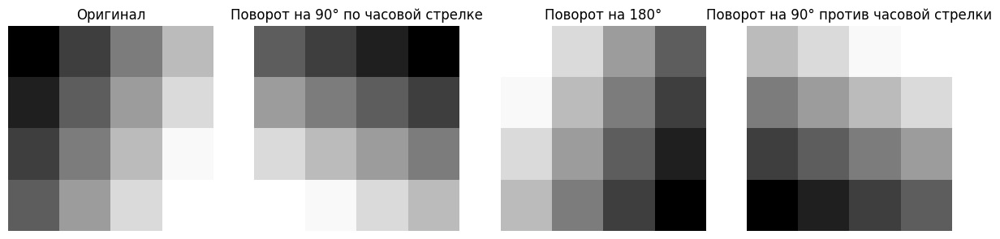

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

print("---Обратите внимание на положения строк и столбцов!---")

# Вывод значений пикселей исходного изображения
print_pixel_values(original, 'Исходное изображение')

# Поворот изображения на 90° по часовой стрелке
rotated_90_clockwise = rotate_image_90_clockwise(original)
print_pixel_values(rotated_90_clockwise, 'Поворот на 90° по часовой стрелке')

# Поворот изображения на 180°
rotated_180 = rotate_image_180(original)
print_pixel_values(rotated_180, 'Поворот на 180°')

# Поворот изображения на 90° против часовой стрелки
rotated_90_counterclockwise = rotate_image_90_counterclockwise(original)
print_pixel_values(rotated_90_counterclockwise, 'Поворот на 90° против часовой стрелки')

# Отображение изображений
images = [original, rotated_90_clockwise, rotated_180, rotated_90_counterclockwise]
titles = ['Оригинал', 'Поворот на 90° по часовой стрелке', 'Поворот на 180°', 'Поворот на 90° против часовой стрелки']
plot_images(images, titles)

**Оптимизация функций с использованием срезов numpy**

Для повышения эффективности можно использовать срезы массивов numpy:

In [ ]:
def rotate_image_90_clockwise(src):
    """
    Поворачивает изображение на 90° по часовой стрелке
    """
    return np.transpose(src[::-1, :], (1, 0, 2)) if src.ndim == 3 else np.transpose(src[::-1, :])

def rotate_image_90_counterclockwise(src):
    """
    Поворачивает изображение на 90° против часовой стрелки
    """
    return np.transpose(src[:, ::-1], (1, 0, 2)) if src.ndim == 3 else np.transpose(src[:, ::-1])

def rotate_image_180(src):
    """
    Поворачивает изображение на 180°
    """
    return src[::-1, ::-1, ...]

Обработаем с помощью этих функций целевое изображение:

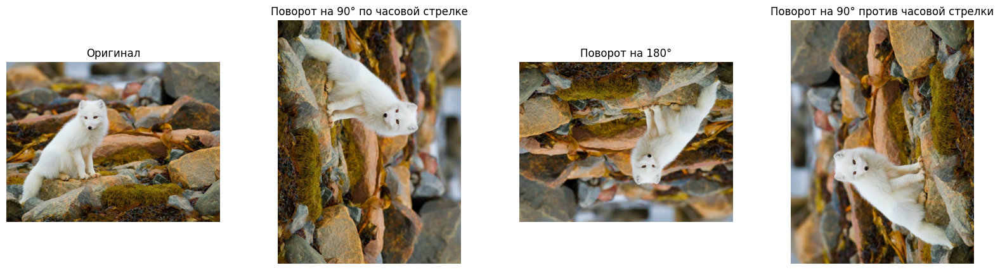

In [ ]:
# Чтение исходного изображения
image = cv2.imread('/content/arctic_fox.jpg')

# Поворот изображения
rotated_images = [
    ('Оригинал', image),
    ('Поворот на 90° по часовой стрелке', rotate_image_90_clockwise(image)),
    ('Поворот на 180°', rotate_image_180(image)),
    ('Поворот на 90° против часовой стрелки', rotate_image_90_counterclockwise(image)),
]

# Отображение изображений в один ряд
plt.figure(figsize=(20, 5))

for i, (title, img) in enumerate(rotated_images, 1):
    plt.subplot(1, 4, i)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis('off')

plt.show()



**Пояснение к оптимизированным функциям:**

- **`np.transpose`** меняет местами оси массива, что соответствует повороту изображения.
- **Срезы `[::-1]`** инвертируют порядок элементов по соответствующей оси.



### **2.2. Зеркальное отражение  (метод `cv2.flip()`)**



**Метод `cv2.flip()`** используется для зеркального отражения изображения по горизонтали, вертикали или одновременно по обеим осям.

**Синтаксис метода `cv2.flip()`:**

```python
dst = cv2.flip(src, flipCode)
```

Где:
- `src` — исходное изображение, которое мы хотим отразить.
- `flipCode` — код, указывающий направление отражения:
  - `0`: отражение по горизонтальной оси (оси x).
  - `> 0`: отражение по вертикальной оси (оси y).
  - `< 0`: отражение и по горизонтальной, и по вертикальной оси (поворот на 180 градусов).
- `dst` — результат отражения, это то же изображение после применения операции зеркального отражения.


`cv2.flip()` полезен, когда требуется отразить изображение для визуальных эффектов, предобработки данных в задачах машинного обучения, где данные нужно аугментировать, или в ситуациях, когда изображение должно быть отражено из-за особенностей его захвата (например, селфи-камеры часто отражают изображение).

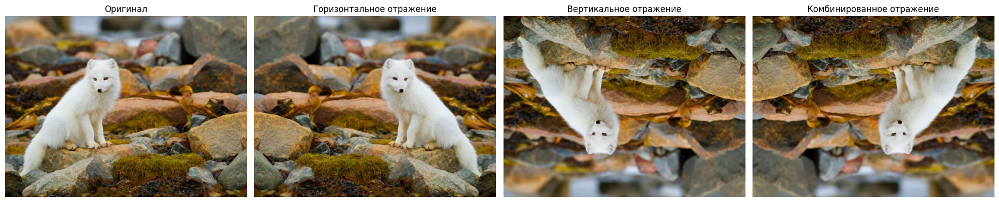

In [ ]:
import cv2
import matplotlib.pyplot as plt

# Считывание изображения
image = cv2.imread('/content/arctic_fox.jpg')

# Горизонтальное отражение
flipped_horizontal = cv2.flip(image, 1)

# Вертикальное отражение
flipped_vertical = cv2.flip(image, 0)

# Комбинированное отражение (по обеим осям)
flipped_both = cv2.flip(image, -1)

# Создание фигуры с подграфиками
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

# Отображение оригинального изображения
axes[0].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
axes[0].set_title('Оригинал')
axes[0].axis('off')

# Отображение горизонтального отраения
axes[1].imshow(cv2.cvtColor(flipped_horizontal, cv2.COLOR_BGR2RGB))
axes[1].set_title('Горизонтальное отражение')
axes[1].axis('off')

# Отображение вертикального отраения
axes[2].imshow(cv2.cvtColor(flipped_vertical, cv2.COLOR_BGR2RGB))
axes[2].set_title('Вертикальное отражение')
axes[2].axis('off')

# Отображение комбинированного отраения
axes[3].imshow(cv2.cvtColor(flipped_both, cv2.COLOR_BGR2RGB))
axes[3].set_title('Комбинированное отражение')
axes[3].axis('off')

# Удаление лишних отступов и отображение изображений
plt.tight_layout()
plt.show()

#### **Математический аппарат**

  При обработке изображений часто требуется выполнить отражение по горизонтальной или вертикальной оси. Это можно описать с помощью математических формул, определяющих, как меняются координаты пикселей при отражении.

  Пусть у нас есть изображение `src` размером $H \times W$, где:
  - $H$ — высота изображения (количество строк),
  - $W$ — ширина изображения (количество столбцов).

  Каждый пиксель изображения можно обозначить как $src_{i,j}$, где:
  - $i \in [0, H - 1]$ — индекс строки,
  - $j \in [0, W - 1]$ — индекс столбца.

**1. Отражение по горизонтальной оси (оси x):**

При отражении по горизонтальной оси строки изображения переставляются в обратном порядке. Формула для получения нового изображения `dst`:

$$
dst_{i,j} = src_{H - i - 1,\ j}
$$

Это означает, что:
- Первая строка ($i = 0$) становится последней ($H - 1$),
- Вторая ($i = 1$) — предпоследней ($H - 2$) и так далее.

**2. Отражение по вертикальной оси (оси y):**

При отражении по вертикальной оси столбцы изображения переставляются в обратном порядке:

$$
dst_{i,j} = src_{i,\ W - j - 1}
$$

Это означает, что:
- Первый столбец ($j = 0$) становится последним ($W - 1$),
- Второй ($j = 1$) — предпоследним ($W - 2$) и так далее.

**3. Отражение по обеим осям:**

При одновременном отражении по горизонтальной и вертикальной осям строки и столбцы меняются местами:

$$
dst_{i,j} = src_{H - i - 1,\ W - j - 1}
$$

Это эквивалентно повороту изображения на $180$ градусов.

#### **Собственная реализация функции для отражения изображений:**

Ниже представлена функция на Python, которая реализует отражение изображений по заданным формулам без использования метода `cv2.flip()`. Функция принимает исходное изображение и код отражения, возвращая отраженное изображение.

In [ ]:
import numpy as np

def flip_image_manual(src, flip_code):
    """
    Отражает изображение по заданному направлению.

    Параметры:
    ----------
    src : numpy.ndarray
        Исходное изображение.
    flip_code : int
        Код направления отражения:
        - 0 : отражение по горизонтальной оси (по оси x).
        - >0 : отражение по вертикальной оси (по оси y).
        - <0 : отражение по горизонтальной и вертикальной осям.

    Возвращает:
    -----------
    dst : numpy.ndarray
        Отраженное изображение.
    """
    # Проверяем, является ли входное изображение трехмерным (цветным)
    if len(src.shape) == 3:
        H, W, C = src.shape  # Высота, ширина, количество каналов
    else:
        H, W = src.shape     # Для grayscale изображений
        C = 1                # Один канал

    # Создаем пустой массив для результирующего изображения
    dst = np.zeros_like(src)

    # Отражение по горизонтальной оси
    if flip_code == 0:
        for i in range(H):
            for j in range(W):
                # Применяем формулу отражения по горизонтальной оси
                dst[i, j] = src[H - i - 1, j]

    # Отражение по вертикальной оси
    elif flip_code > 0:
        for i in range(H):
            for j in range(W):
                # Применяем формулу отражения по вертикальной оси
                dst[i, j] = src[i, W - j - 1]

    # Отражение по обеим осям
    else:
        for i in range(H):
            for j in range(W):
                # Применяем формулу отражения по обеим осям
                dst[i, j] = src[H - i - 1, W - j - 1]

    return dst

Обработаем с помощью написанных функций тестовое изображении с размерностью 4х4 пикселя:

---Обратите внимание на положения строк и столбцов!---

Исходное изображение:
[[ 50 100 150 200]
 [ 75 125 175 225]
 [100 150 200 250]
 [125 175 225 255]]

Отражение по горизонтальной оси (вертикальное отражение):
[[125 175 225 255]
 [100 150 200 250]
 [ 75 125 175 225]
 [ 50 100 150 200]]

Отражение по вертикальной оси (горизонтальное отражение):
[[200 150 100  50]
 [225 175 125  75]
 [250 200 150 100]
 [255 225 175 125]]

Отражение по обеим осям:
[[255 225 175 125]
 [250 200 150 100]
 [225 175 125  75]
 [200 150 100  50]]


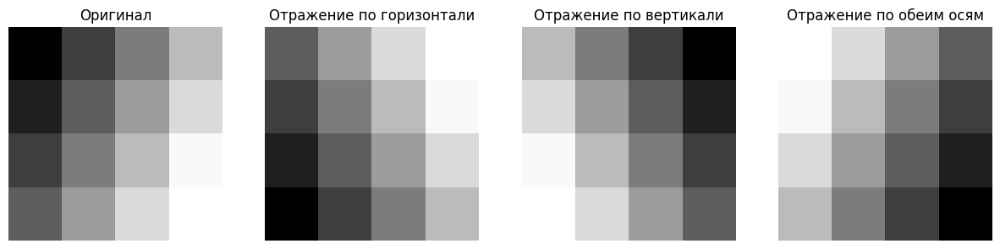

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

print("---Обратите внимание на положения строк и столбцов!---")

# Вывод значений пикселей исходного изображения
print_pixel_values(original, 'Исходное изображение')

# Отражение по горизонтальной оси (вертикальное отражение)
flipped_horizontal = flip_image_manual(original, 0)
print_pixel_values(flipped_horizontal, 'Отражение по горизонтальной оси (вертикальное отражение)')

# Отражение по вертикальной оси (горизонтальное отражение)
flipped_vertical = flip_image_manual(original, 1)
print_pixel_values(flipped_vertical, 'Отражение по вертикальной оси (горизонтальное отражение)')

# Отражение по обеим осям
flipped_both = flip_image_manual(original, -1)
print_pixel_values(flipped_both, 'Отражение по обеим осям')

# Отображение изображений
images = [original, flipped_horizontal, flipped_vertical, flipped_both]
titles = ['Оригинал', 'Отражение по горизонтали', 'Отражение по вертикали', 'Отражение по обеим осям']
plot_images(images, titles)



**Пояснение к функции:**

- **Функция `flip_image_manual`:** Принимает на вход изображение и код отражения.

- **Определение размеров изображения:**
  - Если изображение цветное (трехканальное), оно имеет форму `(H, W, C)`, где `C` — количество цветовых каналов (обычно 3 для RGB).
  - Если изображение черно-белое (одноканальное), оно имеет форму `(H, W)`.

- **Инициализация результирующего изображения `dst`:**
  - Создаем пустой массив того же размера и типа, что и исходное изображение, используя `np.zeros_like(src)`.

- **Отражение по горизонтальной оси (`flip_code == 0`):**
  - Проходим по всем пикселям изображения с помощью вложенных циклов `for`.
  - Для каждого пикселя `(i, j)` целевого изображения берем значение из пикселя `(H - i - 1, j)` исходного изображения согласно формуле.
  - Это инвертирует порядок строк, отражая изображение по горизонтальной оси.

- **Отражение по вертикальной оси (`flip_code > 0`):**
  - Для каждого пикселя `(i, j)` целевого изображения берем значение из пикселя `(i, W - j - 1)` исходного изображения.
  - Это инвертирует порядок столбцов, отражая изображение по вертикальной оси.

- **Отражение по обеим осям (`flip_code < 0`):**
  - Для каждого пикселя `(i, j)` целевого изображения берем значение из пикселя `(H - i - 1, W - j - 1)` исходного изображения.
  - Это инвертирует и строки, и столбцы, отражая изображение по обеим осям.

- **Возвращаем результирующее изображение `dst`.**



#### **Оптимизация функции с использованием срезов numpy:**

Для повышения производительности можно использовать срезы numpy вместо вложенных циклов:

In [ ]:
def flip_image_manual(src, flip_code):
    """
    Оптимизированная функция отражения изображения по заданному направлению.
    """
    if flip_code == 0:
        # Отражение по горизонтали
        dst = src[::-1, :, ...]
    elif flip_code > 0:
        # Отражение по вертикали
        dst = src[:, ::-1, ...]
    else:
        # Отражение по обеим осям
        dst = src[::-1, ::-1, ...]

    return dst

**Пояснение к оптимизированной функции:**

- **Срезы `[::-1]`:** Позволяют инвертировать порядок элементов по заданной оси без использования циклов.
  - `src[::-1, :, ...]` инвертирует строки (ось 0).
  - `src[:, ::-1, ...]` инвертирует столбцы (ось 1).
  - `...` используется для поддержки изображений с произвольным количеством каналов (как 2D, так и 3D).

- **Отражение по обеим осям:**
  - `src[::-1, ::-1, ...]` инвертирует и строки, и столбцы.

Обработаем с помощью этих функций целевое изображение:

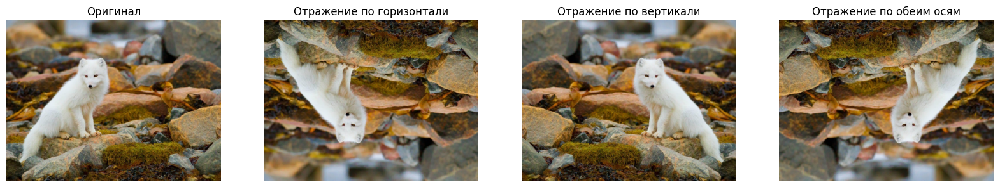

In [ ]:
# Считывание изображения
image = cv2.imread('/content/arctic_fox.jpg')

# Применение функции отражения
flipped_horizontal = flip_image_manual(image, 0)    # Отражение по горизонтали
flipped_vertical = flip_image_manual(image, 1)      # Отражение по вертикали
flipped_both = flip_image_manual(image, -1)         # Отражение по обеим осям

# Отображение изображений в один ряд
plt.figure(figsize=(20, 5))

plt.subplot(1, 4, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title('Оригинал')
plt.axis('off')

plt.subplot(1, 4, 2)
plt.imshow(cv2.cvtColor(flipped_horizontal, cv2.COLOR_BGR2RGB))
plt.title('Отражение по горизонтали')
plt.axis('off')

plt.subplot(1, 4, 3)
plt.imshow(cv2.cvtColor(flipped_vertical, cv2.COLOR_BGR2RGB))
plt.title('Отражение по вертикали')
plt.axis('off')

plt.subplot(1, 4, 4)
plt.imshow(cv2.cvtColor(flipped_both, cv2.COLOR_BGR2RGB))
plt.title('Отражение по обеим осям')
plt.axis('off')

plt.show()

### **2.3. Транспонирование изображений с помощью `cv2.transpose()`**



Метод `cv2.transpose()` выполняет транспонирование изображения, то есть меняет местами строки и столбцы. Это эквивалентно повороту изображения на 90° по часовой стрелке с последующим отражением по горизонтали.

**Синтаксис метода:**

```python
transposed_image = cv2.transpose(src)
```

**Параметры метода:**

- `src` — исходное изображение, которое нужно транспонировать.

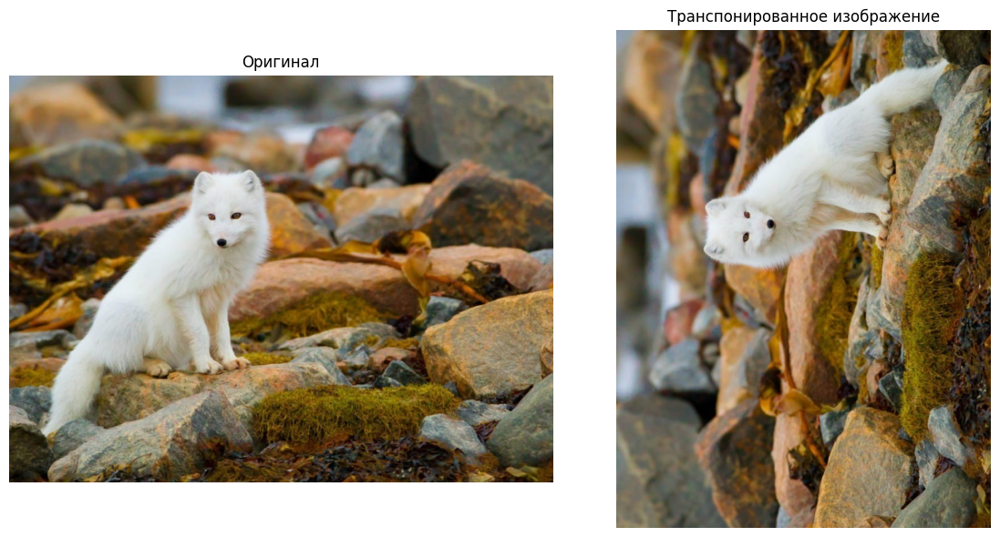

In [ ]:
import cv2
import matplotlib.pyplot as plt

# Считывание изображения
image = cv2.imread('/content/arctic_fox.jpg')

# Транспонирование изображения
transposed_image = cv2.transpose(image)

# Создание фигуры и подграфиков
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Отображение оригинального изображения
axes[0].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
axes[0].set_title('Оригинал')
axes[0].axis('off')

# Отображение транспонированного изображения
axes[1].imshow(cv2.cvtColor(transposed_image, cv2.COLOR_BGR2RGB))
axes[1].set_title('Транспонированное изображение')
axes[1].axis('off')

# Удаление лишних отступов и отображение изображений
plt.tight_layout()
plt.show()

При транспонировании изображения происходит смена осей: пиксели, расположенные по горизонтали, становятся расположенными по вертикали, и наоборот. Это полезно для различных задач обработки изображений, где требуется переориентация изображения.

### **2.4. Обрезка изображений (выделение области интереса) с помощью срезов NumPy**



Для обрезки изображений и выделения области интереса (ROI — Region of Interest) можно использовать срезы массивов в NumPy, поскольку изображения в OpenCV представлены в виде массивов NumPy.

#### Пример №1. Обрезка изображения с использованием фиксированных координат (ROI)

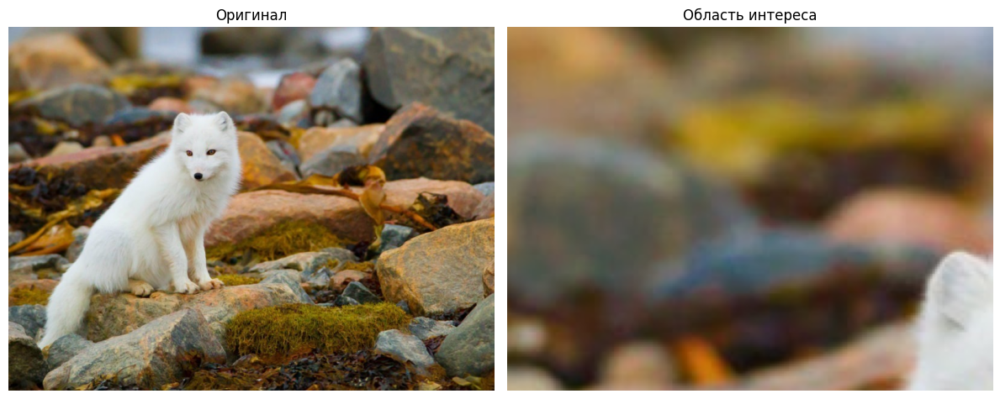

In [ ]:
import cv2
import matplotlib.pyplot as plt

# Считывание изображения
image = cv2.imread('/content/arctic_fox.jpg')

# Определение координат области интереса
# Формат: image[начальная_строка:конечная_строка, начальный_столбец:конечный_столбец]
roi = image[50:200, 100:300]

# Создание фигуры и подграфиков
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Отображение оригинального изображения
axes[0].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
axes[0].set_title('Оригинал')
axes[0].axis('off')

# Отображение области интереса
axes[1].imshow(cv2.cvtColor(roi, cv2.COLOR_BGR2RGB))
axes[1].set_title('Область интереса')
axes[1].axis('off')

# Удаление лишних отступов и отображение изображений
plt.tight_layout()
plt.show()

**Пояснение параметров:**

- `50:200` — диапазон строк (по оси Y) от 50 до 200 пикселей.
- `100:300` — диапазон столбцов (по оси X) от 100 до 300 пикселей.
- `roi` — выделенная область интереса из исходного изображения.


#### Пример №2. Обрезка изображения с использованием процентных соотношений от размеров изображения

In [ ]:
h, w = image.shape[:2]

# start_row и start_col определяют координаты верхнего левого угла прямоугольника обрезки.
# Они вычисляются как 25% и 15% соответственно от высоты и ширины изображения.
start_row, start_col = int(h*0.25), int(w*0.15)

# end_row и end_col определяют координаты нижнего правого угла прямоугольника
# обрезки. Они вычисляются как 75% и 85% соответственно от высоты и ширины изображения.
end_row, end_col = int(h*0.75), int(w*0.85)

# cropped содержит обрезанную часть изображения, которая ограничена заданным
# прямоугольником обрезки. Она вычисляется путем извлечения среза изображения,
# начиная с start_row и start_col и заканчивая end_row и end_col.
cropped = image[start_row:end_row, start_col:end_col]

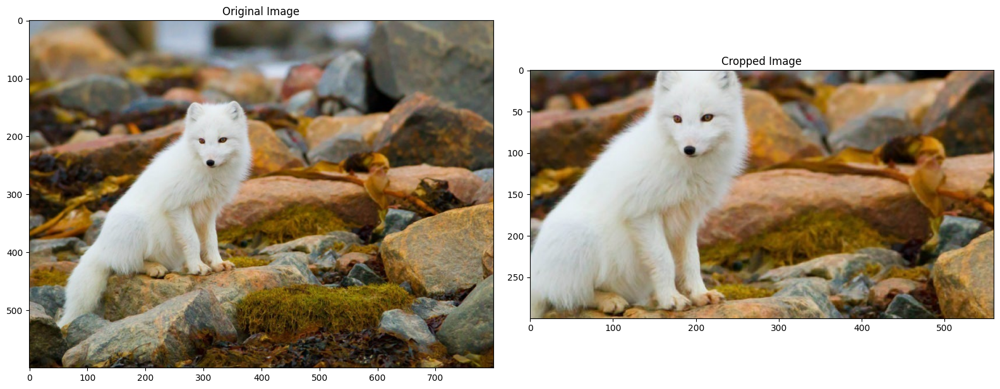

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(16, 8))
fig.tight_layout()

ax[0].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
ax[0].set_title("Original Image")

ax[1].imshow(cv2.cvtColor(cropped, cv2.COLOR_BGR2RGB))
ax[1].set_title("Cropped Image")

plt.show()

### **2.5. Масштабирование, изменение размеров и интерполяция**

Функция `cv.resize()` в библиотеке OpenCV используется для изменения размера изображения. Давайте рассмотрим её параметры и то, как она работает математически.

**Синтаксис функции:**
```python
cv.resize(src, dsize[, dst[, fx[, fy[, interpolation]]]])
```

**Параметры:**
- `src`: Исходное изображение.
- `dsize`: Размер выходного изображения (ширина и высота). Если параметр установлен в (0, 0), то размер вычисляется из коэффициентов масштабирования `fx` и `fy`.
- `dst`: Выходное изображение, которое имеет тот же тип, что и исходное.
- `fx`: Коэффициент масштабирования по горизонтали (ширина).
- `fy`: Коэффициент масштабирования по вертикали (высота).
- `interpolation`: Метод интерполяции. Это важный параметр, определяющий алгоритм, используемый при масштабировании. Наиболее часто используемые методы:

  - `cv.INTER_NEAREST`: Ближайший сосед - простейший метод, выбирается значение ближайшего пикселя к новой точке без учета других пикселей. Может привести к резким краям и пикселизации.
  - `cv.INTER_LINEAR`: Билинейная интерполяция - учитывает четыре соседних пикселя для вычисления значения нового пикселя. Хороший компромисс между скоростью и качеством.
  - `cv.INTER_CUBIC`: Бикубическая интерполяция - учитывает 16 соседних пикселей для вычисления значения нового пикселя. Обеспечивает более гладкую и качественную картинку.
  - `cv.INTER_LANCZOS4`: Интерполяция Ланцоша - использует окно Ланцоша для интерполяции. Обычно обеспечивает очень высокое качество изображения.

#### **Математическое обоснование:**

Когда размер изображения изменяется, каждый новый пиксель нового изображения должен быть вычислен на основе пикселей исходного изображения. Это делается с помощью процесса, называемого интерполяцией.






- #### 1. Для **ближайшего соседа** (`INTER_NEAREST`), новый пиксель получает значение ближайшего пикселя в исходном изображении. Можно рассмотреть это как отображение координат нового пикселя [![\\ $$ (x', y') $$](https://latex.codecogs.com/svg.latex?%5C%5C%20%5C(%20(x'%2C%20y')%20%5C))](#_) назад в исходное изображение [![\\ $$ (x, y) $$](https://latex.codecogs.com/svg.latex?%5C%5C%20%5C(%20(x%2C%20y)%20%5C))](#_):
   [![\\ x = \frac{x'}{fx}, \quad y = \frac{y'}{fy} ](https://latex.codecogs.com/svg.latex?%5C%5C%20x%20%3D%20%5Cfrac%7Bx'%7D%7Bfx%7D%2C%20%5Cquad%20y%20%3D%20%5Cfrac%7By'%7D%7Bfy%7D%20)](#_)
   
   Затем используется значение [![\\ $$(x, y)$$](https://latex.codecogs.com/svg.latex?%5C%5C%20%5C((x%2C%20y)%5C))](#_) в исходном изображении для нового пикселя.

#### **Программная реализация:**

Исходное изображение:
[[ 50 100 150 200]
 [ 75 125 175 225]
 [100 150 200 250]
 [125 175 225 255]]

Результат интерполяции методом ближайшего соседа:
[[ 50  50 100 100 150 150 200 200]
 [ 50  50 100 100 150 150 200 200]
 [ 75  75 125 125 175 175 225 225]
 [ 75  75 125 125 175 175 225 225]
 [100 100 150 150 200 200 250 250]
 [100 100 150 150 200 200 250 250]
 [125 125 175 175 225 225 255 255]
 [125 125 175 175 225 225 255 255]]



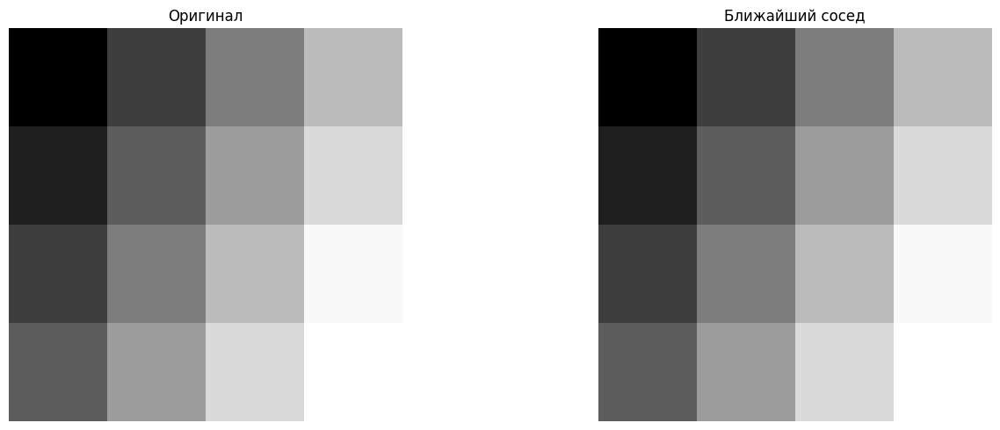

In [ ]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

def nearest_neighbor(img, scale):
    # Определяем размеры исходного изображения
    height, width = img.shape[:2]
    # Вычисляем размеры нового изображения
    new_height, new_width = int(height * scale), int(width * scale)

    # Проверяем количество каналов в изображении
    if img.ndim == 2:
        # Если изображение черно-белое, добавляем измерение для унификации обработки
        img = img[:, :, np.newaxis]
        channels = 1
    else:
        channels = img.shape[2]

    # Создаем пустое изображение для результата
    new_img = np.zeros((new_height, new_width, channels), dtype=img.dtype)

    # Отношения масштабирования
    row_scale = height / new_height
    col_scale = width / new_width

    # Проходим по каждому каналу
    for c in range(channels):
        # Проходим по каждому пикселю нового изображения
        for i in range(new_height):
            for j in range(new_width):
                # Обратное преобразование координат
                orig_x = int(j * col_scale)
                orig_y = int(i * row_scale)

                # Ограничиваем координаты, чтобы не выйти за границы исходного изображения
                orig_x = min(orig_x, width - 1)
                orig_y = min(orig_y, height - 1)

                # Присваиваем значение ближайшего соседа
                new_img[i, j, c] = img[orig_y, orig_x, c]

    # Если изображение было черно-белым, убираем дополнительное измерение
    if channels == 1:
        new_img = new_img.reshape((new_height, new_width))

    return new_img


# Выводим значения пикселей исходного изображения
print_pixel_values(original, "Исходное изображение")
# Применяем интерполяцию методом ближайшего соседа
nn_result = nearest_neighbor(original, 2)
# Выводим значения пикселей интерполированного изображения
print_pixel_values(nn_result, "Результат интерполяции методом ближайшего соседа")
# Отображаем изображения
plot_images([original, nn_result], ['Оригинал', 'Ближайший сосед'])

**Принцип работы кода и роль коэффициентов масштабирования:**

1. **Подготовка:**
   - **Размеры исходного изображения:** Получаем высоту (`height`) и ширину (`width`) с помощью `img.shape[:2]`.
   - **Новые размеры:** Вычисляем `new_height` и `new_width`, умножая исходные размеры на коэффициент масштабирования `scale`.

2. **Обработка каналов:**
   - Проверяем, является ли изображение черно-белым или цветным.
   - Если черно-белое, добавляем измерение для унификации.
   - Определяем количество каналов (`channels`).

3. **Создание нового изображения:**
   - Инициализируем пустой массив `new_img` с новыми размерами и количеством каналов.

4. **Коэффициенты масштабирования:\***
   - **По высоте:** `row_scale = height / new_height`.
   - **По ширине:** `col_scale = width / new_width`.
   - Эти коэффициенты отражают отношение размеров исходного изображения к новому и используются для преобразования координат.

5. **Масштабирование:**
   - **Циклы по каналам и пикселям:**
     - Проходим по каждому каналу `c`.
     - Для каждого пикселя нового изображения с координатами `(i, j)`:
       - **Обратное преобразование координат:**
         - Вычисляем исходные координаты:
           - `orig_x = int(j * col_scale)`
           - `orig_y = int(i * row_scale)`
       - **Ограничение координат:**
         - Убеждаемся, что `orig_x` ≤ `width - 1` и `orig_y` ≤ `height - 1`.
       - **Присвоение значения пикселя:**
         - Пикселю `[i, j, c]` присваиваем значение `[orig_y, orig_x, c]` из исходного изображения.

6. **Завершение:**
   - Если изображение было черно-белым, удаляем добавленное измерение.
   - Возвращаем масштабированное изображение `new_img`.
---

**\*Роль коэффициентов масштабирования:**

- `row_scale` и `col_scale` показывают отношение размеров исходного изображения к новому.

**Пример:**

Например, если в исходном изображении пиксель с координатами `(orig_y, orig_x)` имеет значение 128, то при масштабировании методом ближайшего соседа это значение будет присвоено соответствующим пикселям в новом изображении.

Допустим, мы масштабируем изображение в **2 раза** (`scale = 2`). Коэффициенты масштабирования будут:

- По вертикали (высота):
  ```
  row_scale = height / new_height = 1 / 2 = 0.5
  ```
- По горизонтали (ширина):
  ```
  col_scale = width / new_width = 1 / 2 = 0.5
  ```

**Как они помогают:**

1. **Обратное преобразование координат:**
   - Для каждого пикселя нового изображения с координатами `(i, j)` мы вычисляем координаты в исходном изображении:
     ```
     orig_x = int(j * col_scale)
     orig_y = int(i * row_scale)
     ```
     Это позволяет определить, какой пиксель из исходного изображения соответствует текущему пикселю нового изображения.

2. **Пример:**
   - Рассмотрим пиксель нового изображения с координатами `(i = 4, j = 6)`:
     ```
     orig_x = int(6 * 0.5) = int(3) = 3
     orig_y = int(4 * 0.5) = int(2) = 2
     ```
     Это означает, что пиксель в новом изображении `(4, 6)` возьмёт значение из пикселя исходного изображения `(2, 3)`.

   - **Если** пиксель исходного изображения `(2, 3)` имеет значение **128**, то пиксель нового изображения `(4, 6)` тоже будет иметь значение **128**.

3. **Повторение значений:**
   - Поскольку коэффициенты масштабирования меньше 1 при увеличении изображения, один и тот же пиксель из исходного изображения будет соответствовать нескольким пикселям в новом изображении.
   - Это приводит к "растяжению" изображения, при котором оригинальные пиксели копируются на большее количество позиций в новом изображении.

**Таким образом, коэффициенты масштабирования помогают:**

- **Сопоставить пиксели** нового изображения с соответствующими пикселями исходного изображения.
- **Сохранить визуальную целостность** изображения при масштабировании, минимизируя искажения.
- **Обеспечить корректное масштабирование** как при увеличении, так и при уменьшении изображения.

**В итоговом изображении** каждый пиксель получает значение ближайшего соответствующего пикселя из исходного изображения, что обеспечивает быстрое и простое масштабирование с минимальными вычислительными затратами.

---

####  **2. Билинейная интерполяция** (`INTER_LINEAR`) является методом интерполяции, который учитывает значения четырех ближайших пикселей вокруг целевого положения в исходном изображении. Этот метод обеспечивает более гладкие результаты по сравнению с методом ближайшего соседа, но может привести к некоторому размытию изображения.

 2.1. **Математический аппарат:**

  - Билинейная интерполяция вычисляет значение пикселя в точке $ (x, y) $ на основе значений четырех ближайших пикселей $ Q_{11}, \; Q_{12}, \; Q_{21}, \; Q_{22} $ с координатами $ (x_1, y_1), \; (x_1, y_2), \; (x_2, y_1), \; (x_2, y_2) $ соответственно.

 2.2. **Общая формула билинейной интерполяции:**

  $$
  \begin{align}
  f(x, y) = & \, f(Q_{11}) \cdot (x_2 - x) \cdot (y_2 - y) \\
  & + f(Q_{21}) \cdot (x - x_1) \cdot (y_2 - y) \\
  & + f(Q_{12}) \cdot (x_2 - x) \cdot (y - y_1) \\
  & + f(Q_{22}) \cdot (x - x_1) \cdot (y - y_1)
  \end{align}
  $$

  - где:

    - $f(x, y)$ — интерполированное значение в точке $(x, y)$.
    - $x_1 \leq x \leq x_2 $, $ y_1 \leq y \leq y_2$.
    - $ f(Q_{ij})$ — значение пикселя в точке $ Q_{ij}$.


Билинейная интерполяция линейна по каждому из направлений и учитывает значения пикселей как по оси $ x $, так и по оси $ y $.

#### **Программная реализация:**


Исходное изображение:
[[ 50 100 150 200]
 [ 75 125 175 225]
 [100 150 200 250]
 [125 175 225 255]]

Результат билинейной интерполяции:
[[ 50  75 100 125 150 175 200 200]
 [ 62  87 112 137 162 187 212 212]
 [ 75 100 125 150 175 200 225 225]
 [ 87 112 137 162 187 212 237 237]
 [100 125 150 175 200 225 250 250]
 [112 137 162 187 212 232 252 252]
 [125 150 175 200 225 240 255 255]
 [125 150 175 200 225 240 255 255]]


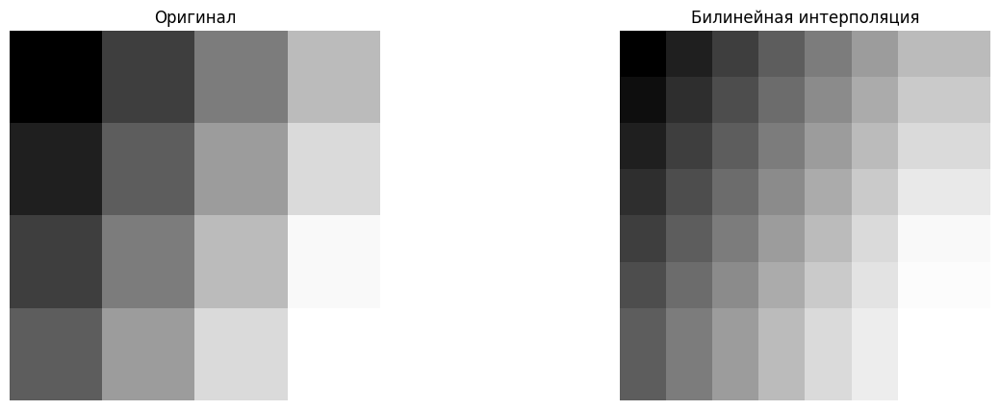

In [ ]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

def bilinear(img, scale):
    # Преобразуем изображение в тип float32 для повышенной точности вычислений
    img = img.astype(np.float32)
    height, width = img.shape[:2]
    new_height, new_width = int(height * scale), int(width * scale)

    # Проверяем, является ли изображение цветным или черно-белым
    if img.ndim == 2:
        # Для черно-белого изображения добавляем измерение для унификации обработки
        img = img[:, :, np.newaxis]
        channels = 1
    else:
        channels = img.shape[2]

    # Создаем пустое изображение для результата
    new_img = np.zeros((new_height, new_width, channels), dtype=np.float32)

    for c in range(channels):
        for i in range(new_height):
            for j in range(new_width):
                # Обратное преобразование координат
                x = j / scale
                y = i / scale

                # Координаты четырех соседних пикселей
                x1 = int(np.floor(x))
                y1 = int(np.floor(y))
                x2 = min(x1 + 1, width - 1)
                y2 = min(y1 + 1, height - 1)

                # Доли от расстояний до соседних пикселей
                dx = x - x1
                dy = y - y1

                # Значения четырех соседних пикселей
                Q11 = img[y1, x1, c]
                Q12 = img[y2, x1, c]
                Q21 = img[y1, x2, c]
                Q22 = img[y2, x2, c]

                # Вычисляем интерполированное значение
                value = (Q11 * (1 - dx) * (1 - dy) +
                         Q21 * dx * (1 - dy) +
                         Q12 * (1 - dx) * dy +
                         Q22 * dx * dy)

                new_img[i, j, c] = value

    # Если изображение было черно-белым, удаляем добавленное измерение
    if channels == 1:
        new_img = new_img.reshape((new_height, new_width))

    # Ограничиваем значения в диапазоне [0, 255] и преобразуем в uint8
    new_img = np.clip(new_img, 0, 255).astype(np.uint8)
    return new_img


print_pixel_values(original, "Исходное изображение")
bilinear_result = bilinear(original, 2)
print_pixel_values(bilinear_result, "Результат билинейной интерполяции")
plot_images([original, bilinear_result], ['Оригинал', 'Билинейная интерполяция'])

**Объяснение кода:**

1. **Преобразование типа данных:**
   - Изображение преобразуется в тип `float32` для более точных вычислений при интерполяции.

2. **Определение количества каналов:**
   - Если изображение черно-белое (двумерный массив), добавляем новое измерение и устанавливаем количество каналов в 1.
   - Если изображение цветное, количество каналов определяется из исходного изображения.

3. **Масштабирование размеров:**
   - Новые размеры вычисляются исходя из коэффициента масштабирования.

4. **Основной цикл интерполяции:**
   - Проходим по каждому пикселю нового изображения и вычисляем соответствующие координаты в исходном изображении.
   - Определяем четыре ближайших соседних пикселя и их значения.
   - Вычисляем веса на основе расстояния до соседних пикселей.
   - Вычисляем интерполированное значение и записываем его в результирующее изображение.

5. **Постобработка результата:**
   - Ограничиваем значения пикселей в диапазоне [0, 255] с помощью `np.clip`.
   - Преобразуем тип данных обратно в `uint8` для корректного отображения изображения.

6. **Отображение изображений:**
   - Функция `plot_images` отображает исходное и интерполированное изображения.
   - Для цветных изображений выполняется преобразование из BGR в RGB для правильного отображения в Matplotlib.

---

####  **3. Бикубическая интерполяция** (`INTER_CUBIC`)

Бикубическая интерполяция использует значения 16 пикселей (область размером 4×4) вокруг целевой точки для вычисления нового значения пикселя. Новое значение пикселя вычисляется как взвешенная сумма значений соседних пикселей, где веса определяются кубической функцией расстояния до каждой точки.

- **Общая формула бикубической интерполяции:**

$$
f(x, y) = \sum_{k=-1}^{2} \sum_{l=-1}^{2} f(i+k, j+l) \cdot W(x - (i+k)) \cdot W(y - (j+l))
$$

  - где:

    - $ f(x, y) $ — интерполированное значение в точке $ (x, y) $.
    - $ f(i+k, j+l) $ — значение пикселя в соседней точке с координатами $ (i+k, j+l) $.
    - $ W(t) $ — кубическая функция взвешивания расстояния $ t $.
    - $ i $ и $ j $ — целая часть координат $ x $ и $ y $ соответственно.


- **Кубическая функция взвешивания $ W(t) $:**

Функция $ W(t) $ определяется с использованием параметра $ a $ (обычно $ a = -0.5 $, что соответствует сплайну Катмулла–Рома):

$$
W(t) = \begin{cases}
(a + 2)|t|^3 - (a + 3)|t|^2 + 1, & \text{если } |t| \leq 1 \\
a|t|^3 - 5a|t|^2 + 8a|t| - 4a, & \text{если } 1 < |t| < 2 \\
0, & \text{если } |t| \geq 2
\end{cases}
$$

  - При $ a = -0.5 $ функция $ W(t) $ упрощается до:

$$
W(t) = \begin{cases}
1.5|t|^3 - 2.5|t|^2 + 1, & \text{если } |t| \leq 1 \\
-0.5|t|^3 + 2.5|t|^2 - 4|t| + 2, & \text{если } 1 < |t| < 2 \\
0, & \text{если } |t| \geq 2
\end{cases}
$$

**Интерпретация формул:**

- **Интерполяция по осям $ x $ и $ y $:** Бикубическая интерполяция выполняется путем применения кубической интерполяции сначала по оси $ x $, а затем по оси $ y $, используя функцию взвешивания $ W(t) $.
- **Веса соседних пикселей:** Вес каждого из 16 соседних пикселей зависит от расстояния до целевой точки $ (x, y) $ и вычисляется с помощью функции $ W(t) $.
- **Кубическая функция $ W(t) $:** Эта функция обеспечивает плавное взвешивание, уменьшающееся по мере удаления от целевой точки, что способствует получению более гладкого и качественного изображения.

**Преимущества и недостатки:**

- **Преимущества:**
  - Обеспечивает более гладкие и качественные результаты по сравнению с билинейной интерполяцией.
  - Лучше сохраняет детали и текстуры изображения.
- **Недостатки:**
  - Требует больше вычислительных ресурсов из-за использования 16 пикселей и более сложных вычислений.
  - Может создавать небольшие артефакты, такие как негативные кольцевые эффекты (overshoot) вокруг резких переходов.

#### **Программная реализация:**

Исходное изображение:
[[ 50 100 150 200]
 [ 75 125 175 225]
 [100 150 200 250]
 [125 175 225 255]]

Результат бикубической интерполяции:
[[ 50  70 100 125 150 179 200 206]
 [ 60  80 110 135 160 189 210 216]
 [ 75  95 125 150 175 204 225 231]
 [ 87 108 137 162 187 217 238 245]
 [100 120 150 175 200 229 250 255]
 [114 135 164 190 214 238 254 255]
 [125 145 175 201 225 243 255 255]
 [128 148 178 204 228 245 255 255]]



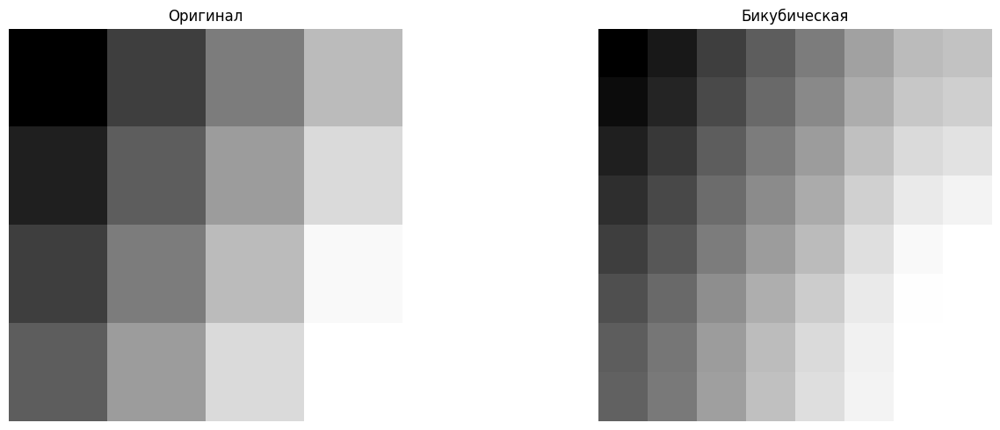

In [ ]:
def cubic(x):
    x = abs(x)
    if x <= 1:
        # Если |x| <= 1, используем первую часть весовой функции
        return (1.5 * x**3 - 2.5 * x**2 + 1)
    elif 1 < x < 2:
        # Если 1 < |x| < 2, используем вторую часть весовой функции
        return (-0.5 * x**3 + 2.5 * x**2 - 4 * x + 2)
    else:
        # Если |x| >= 2, вес равен 0
        return 0

def bicubic(img, scale):
    # Преобразуем изображение в тип float32 для повышенной точности вычислений
    img = img.astype(np.float32)
    height, width = img.shape[:2]
    # Вычисляем новые размеры изображения
    new_height, new_width = int(height * scale), int(width * scale)

    # Проверяем количество каналов в изображении
    if img.ndim == 2:
        # Если изображение черно-белое, добавляем новое измерение для унификации
        channels = 1
        img = img[:, :, np.newaxis]
    else:
        # Если изображение цветное, получаем количество каналов
        channels = img.shape[2]

    # Создаем пустое изображение для хранения результата
    new_img = np.zeros((new_height, new_width, channels), dtype=np.float32)

    # Проходим по каждому каналу
    for c in range(channels):
        # Проходим по каждому пикселю нового изображения по высоте
        for i in range(new_height):
            # Проходим по каждому пикселю нового изображения по ширине
            for j in range(new_width):
                # Вычисляем соответствующие координаты в исходном изображении
                x = j / scale
                y = i / scale

                # Находим целочисленные координаты
                x1 = int(x)
                y1 = int(y)

                # Инициализируем переменные для накопления значений
                total = 0
                weight_sum = 0

                # Проходим по окрестности 4x4 соседних пикселей
                for m in range(-1, 3):
                    for n in range(-1, 3):
                        xm = x1 + m
                        yn = y1 + n

                        # Проверяем, что координаты внутри границ изображения
                        if 0 <= xm < width and 0 <= yn < height:
                            # Вычисляем веса по осям x и y с помощью кубической функции
                            wx = cubic(x - xm)
                            wy = cubic(y - yn)
                            # Общий вес как произведение весов по x и y
                            weight = wx * wy
                            # Накопление взвешенного значения пикселя
                            total += img[yn, xm, c] * weight
                            # Накопление суммарного веса
                            weight_sum += weight

                # Проверяем, чтобы избежать деления на ноль
                if weight_sum != 0:
                    # Вычисляем итоговое значение пикселя путем нормализации
                    new_img[i, j, c] = total / weight_sum
                else:
                    # Если сумма весов равна нулю, устанавливаем пиксель в ноль
                    new_img[i, j, c] = 0

    # Если изображение было черно-белым, убираем дополнительное измерение
    if channels == 1:
        new_img = new_img.reshape((new_height, new_width))

    # Ограничиваем значения пикселей в диапазоне от 0 до 255 и преобразуем в uint8
    new_img = np.clip(new_img, 0, 255).astype(np.uint8)
    return new_img

# Выводим значения пикселей исходного изображения
print_pixel_values(original, "Исходное изображение")

# Применяем функцию бикубической интерполяции с коэффициентом масштабирования 2
bicubic_result = bicubic(original, 2)

# Выводим значения пикселей интерполированного изображения
print_pixel_values(bicubic_result, "Результат бикубической интерполяции")

# Отображаем исходное и интерполированное изображения
plot_images([original, bicubic_result], ['Оригинал', 'Бикубическая'])

#### **4. Интерполяция Ланцоша** (`INTER_LANCZOS4`)

Интерполяция Ланцоша использует окно вокруг целевой точки и рассчитывает веса на основе функции sinc, что позволяет получить более плавные переходы и высококачественные результаты при масштабировании изображений.

**Функция sinc** — это математическая функция, определяемая как:

$$
\text{sinc}(x) =
\begin{cases}
\dfrac{\sin(\pi x)}{\pi x}, & \text{если } x \neq 0 \\
1, & \text{если } x = 0
\end{cases}
$$

То есть она принимает максимальное значение в центре (при $ x = 0 $) и постепенно уменьшается, колеблясь, по мере удаления от центра.

В контексте **обработки сигналов и изображений**, функция sinc используется для идеальной интерполяции — когда необходимо перейти от набора дискретных точек данных к непрерывной функции без потери информации.

Ключевой момент в интерполяции Ланцоша — это использование **окна Ланцоша**. Поскольку идеальная функция sinc имеет бесконечный диапазон и не может быть использована напрямую, окно Ланцоша позволяет "обрезать" функцию sinc, делая её пригодной для практического использования.

**Окно Ланцоша** зависит от параметра $ a $, который определяет размер окна. Обычно увеличение параметра $ a $ улучшает качество интерполяции, но также увеличивает вычислительные затраты.

**Функция окна Ланцоша** определяется как:

$$
L(x) =
\begin{cases}
\text{sinc}(x) \cdot \text{sinc}\left( \dfrac{x}{a} \right), & \text{если } -a < x < a \\
0, & \text{иначе}
\end{cases}
$$

где:

- $ \text{sinc}(x) $ — функция sinc.
- $ a $ — параметр окна Ланцоша.


**Основные шаги интерполяции Ланцоша в контексте изображений:**

  1. **Выборка**: Выбирается набор ближайших пикселей вокруг точки, для которой необходимо определить новое значение цвета или интенсивности. Размер окна определяется параметром $ a $ (обычно $ a = 3 $), что соответствует окну $ 6 \times 6 $ пикселей.

  2. **Вычисление весов**: Каждому из этих пикселей присваивается вес с помощью функции окна Ланцоша $ L(x) $, зависящей от расстояния до целевой точки.

  3. **Суммирование**: Все взвешенные значения пикселей суммируются для получения конечного интерполированного значения в точке.

**Формула интерполяции Ланцоша:**

$$
f(x, y) = \dfrac{ \sum_{k=-a+1}^{a} \sum_{l=-a+1}^{a} f(i+k, j+l) \cdot L(x - (i + k)) \cdot L(y - (j + l)) }{ \sum_{k=-a+1}^{a} \sum_{l=-a+1}^{a} L(x - (i + k)) \cdot L(y - (j + l)) }
$$

где:

- $ f(x, y) $ — интерполированное значение в точке $ (x, y) $.
- $ f(i + k, j + l) $ — значение пикселя в координатах $ (i + k, j + l) $.
- $ L(t) $ — функция окна Ланцоша.
- $ (i, j) $ — целая часть координат $ x $ и $ y $.
- $ k $ и $ l $ — смещения в окне Ланцоша.


> Интерполяция Ланцоша эффективна для уменьшения искажений и сохранения резкости изображения, особенно при работе с высоким разрешением. Это делает её популярным выбором в графических редакторах и приложениях компьютерной графики для масштабирования изображений.




Исходное изображение:
[[ 50 100 150 200]
 [ 75 125 175 225]
 [100 150 200 250]
 [125 175 225 255]]

Результат интерполяции Ланцоша:
[[ 50  65 100 125 150 181 200 208]
 [ 57  73 107 132 157 189 207 216]
 [ 75  90 125 150 175 206 225 233]
 [ 87 103 137 162 187 220 240 249]
 [100 115 150 175 200 231 250 255]
 [115 131 165 192 215 241 254 255]
 [125 140 175 202 225 245 255 255]
 [129 144 179 207 229 247 254 255]]


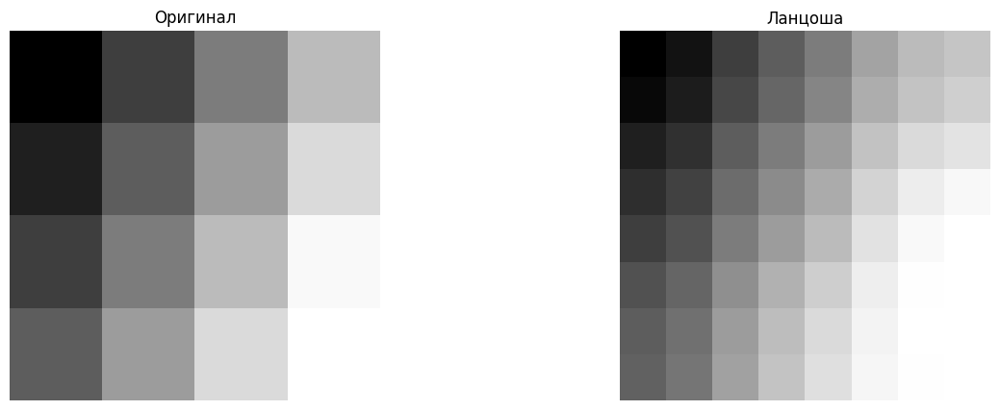

In [ ]:
def sinc(x):
    # Функция sinc согласно определению
    if x == 0:
        return 1
    return np.sin(np.pi * x) / (np.pi * x)

def lanczos(x, a=3):
    # Функция Ланцоша с параметром окна a
    if -a < x < a:
        return sinc(x) * sinc(x / a)
    else:
        return 0

def lanczos_interpolation(img, scale, a=3):
    # Преобразуем изображение в тип float32 для точности вычислений
    img = img.astype(np.float32)
    height, width = img.shape[:2]
    new_height, new_width = int(height * scale), int(width * scale)

    # Проверяем количество каналов
    if img.ndim == 2:
        # Черно-белое изображение
        channels = 1
        img = img[:, :, np.newaxis]
    else:
        # Цветное изображение
        channels = img.shape[2]

    # Создаем пустое изображение для результата
    new_img = np.zeros((new_height, new_width, channels), dtype=np.float32)

    # Проходим по каждому каналу
    for c in range(channels):
        # Проходим по каждому пикселю нового изображения
        for i in range(new_height):
            for j in range(new_width):
                # Обратное преобразование координат
                x = j / scale
                y = i / scale

                x1 = int(x)
                y1 = int(y)

                total = 0
                weight_sum = 0

                # Проходим по окрестности размера окна Ланцоша
                for m in range(-a + 1, a):
                    for n in range(-a + 1, a):
                        xm = x1 + m
                        yn = y1 + n

                        # Проверяем, что координаты внутри границ изображения
                        if 0 <= xm < width and 0 <= yn < height:
                            wx = lanczos(x - xm, a)
                            wy = lanczos(y - yn, a)
                            weight = wx * wy
                            total += img[yn, xm, c] * weight
                            weight_sum += weight

                # Проверяем, чтобы избежать деления на ноль
                if weight_sum != 0:
                    new_img[i, j, c] = total / weight_sum
                else:
                    new_img[i, j, c] = 0

    # Если изображение было черно-белым, убираем дополнительное измерение
    if channels == 1:
        new_img = new_img.reshape((new_height, new_width))

    # Ограничиваем значения пикселей в диапазоне [0, 255] и преобразуем в uint8
    new_img = np.clip(new_img, 0, 255).astype(np.uint8)
    return new_img

# Выводим значения пикселей исходного изображения
print_pixel_values(original, "Исходное изображение")

# Применяем интерполяцию Ланцоша с коэффициентом масштабирования 2
lanczos_result = lanczos_interpolation(original, 2)

# Выводим значения пикселей интерполированного изображения
print_pixel_values(lanczos_result, "Результат интерполяции Ланцоша")

# Отображаем изображения
plot_images([original, lanczos_result], ['Оригинал', 'Ланцоша'])

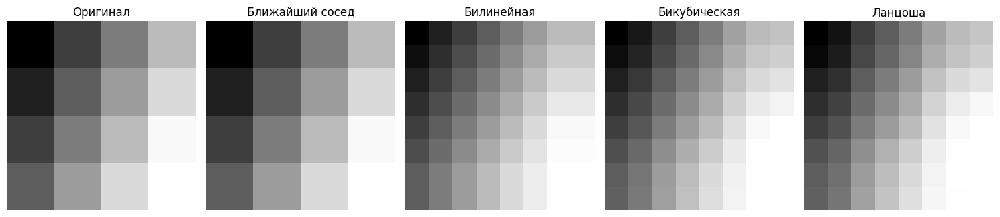


Размер оригинального изображения: (4, 4)
Размер увеличенных изображений: (8, 8)


In [ ]:
# Сравнение всех методов
plot_images([original, nn_result, bilinear_result, bicubic_result, lanczos_result],
            ['Оригинал', 'Ближайший сосед', 'Билинейная', 'Бикубическая', 'Ланцоша'])

# Вывод размеров изображений
print(f"\nРазмер оригинального изображения: {original.shape}")
print(f"Размер увеличенных изображений: {nn_result.shape}")

Применим рассмотренные алгоритмы интерполяции к фрагменту целевого изображения:

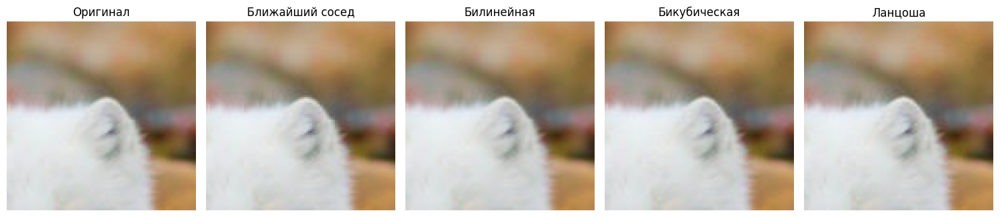


Размер исходного вырезанного изображения: (100, 100, 3)
Размер увеличенных изображений: (200, 200, 3)


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

# Загрузка изображения
image = cv2.imread('/content/arctic_fox.jpg')
# image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Вырезаем часть изображения
x, y, w, h = 300, 100, 100, 100  # Координаты и размеры вырезаемой части
crop = image[y:y+h, x:x+w]

# Применяем методы интерполяции
scale = 2
nn_result = nearest_neighbor(crop, scale)
bilinear_result = bilinear(crop, scale)
bicubic_result = bicubic(crop, scale)
lanczos_result = lanczos_interpolation(crop, scale)


# Отображаем все результаты в ряд
plot_images([crop, nn_result, bilinear_result, bicubic_result, lanczos_result],
            ['Оригинал', 'Ближайший сосед', 'Билинейная', 'Бикубическая', 'Ланцоша'])

# Вывод размеров изображений
print(f"\nРазмер исходного вырезанного изображения: {crop.shape}")
print(f"Размер увеличенных изображений: {nn_result.shape}")

**Повторим процесс интерполяции, используя соответствующие методы OpenCV:**

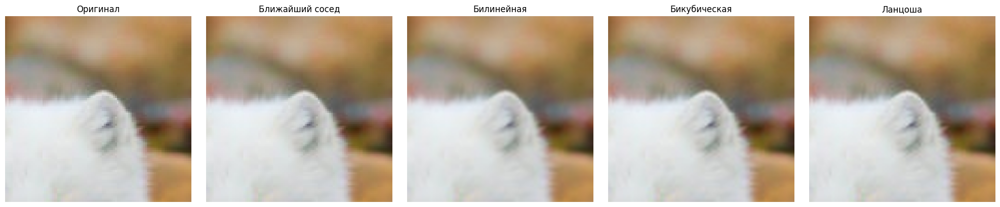


Размер исходного вырезанного изображения: (100, 100, 3)
Размер увеличенных изображений: (200, 200, 3)


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

# Загрузка изображения
image = cv2.imread('/content/arctic_fox.jpg')
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Вырезаем часть изображения
x, y, w, h = 300, 100, 100, 100  # Координаты и размеры вырезаемой части
crop = image[y:y+h, x:x+w]

# Применяем методы интерполяции
scale = 2
nn_result = cv2.resize(crop, None, fx=scale, fy=scale, interpolation=cv2.INTER_NEAREST)
bilinear_result = cv2.resize(crop, None, fx=scale, fy=scale, interpolation=cv2.INTER_LINEAR)
bicubic_result = cv2.resize(crop, None, fx=scale, fy=scale, interpolation=cv2.INTER_CUBIC)
lanczos_result = cv2.resize(crop, None, fx=scale, fy=scale, interpolation=cv2.INTER_LANCZOS4)

# Функция для отображения изображений
def plot_images(images, titles):
    fig, axs = plt.subplots(1, len(images), figsize=(20, 4))
    for i, (img, title) in enumerate(zip(images, titles)):
        axs[i].imshow(img, cmap='gray')
        axs[i].set_title(title)
        axs[i].axis('off')
    plt.tight_layout()
    plt.show()

# Отображаем все результаты в ряд
plot_images([crop, nn_result, bilinear_result, bicubic_result, lanczos_result],
            ['Оригинал', 'Ближайший сосед', 'Билинейная', 'Бикубическая', 'Ланцоша'])

# Вывод размеров изображений
print(f"\nРазмер исходного вырезанного изображения: {crop.shape}")
print(f"Размер увеличенных изображений: {nn_result.shape}")

**Пример увеличения разрешения изображения (апскейла), используя изученные методы интерполяции:**

In [ ]:
# Ссылка на файл для скачивания
url = r'https://sun9-25.userapi.com/DfeMcz4mRPeYwjL3eWyar8eMCsDU66n3o16DhQ/040OOqXUVuU.jpg'

# Скачиваем файл с помощью wget
!wget -O low_arctic_fox.jpg '{url}'

--2024-10-16 14:18:04--  https://sun9-25.userapi.com/DfeMcz4mRPeYwjL3eWyar8eMCsDU66n3o16DhQ/040OOqXUVuU.jpg
Resolving sun9-25.userapi.com (sun9-25.userapi.com)... 93.186.227.136
Connecting to sun9-25.userapi.com (sun9-25.userapi.com)|93.186.227.136|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 25049 (24K) [image/jpeg]
Saving to: ‘low_arctic_fox.jpg’

low_arctic_fox.jpg  100%[===================>]  24.46K  --.-KB/s    in 0s      

2024-10-16 14:18:05 (118 MB/s) - ‘low_arctic_fox.jpg’ saved [25049/25049]



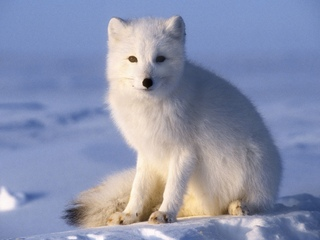

Исходное изображение с низким разрешением


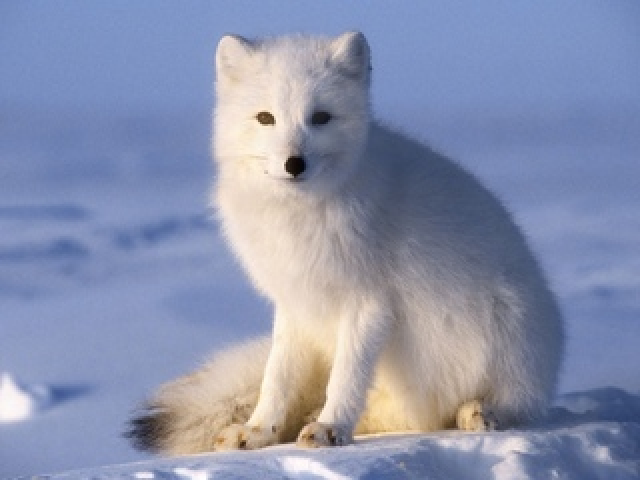

Метод ближайшего соседа (INTER_NEAREST)


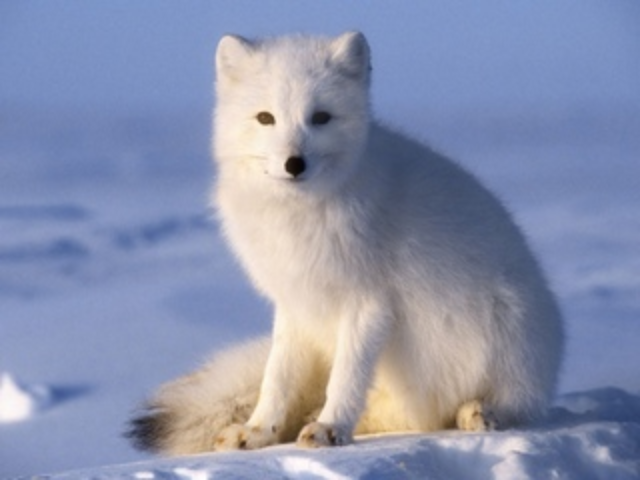

Билинейная интерполяция (INTER_LINEAR)


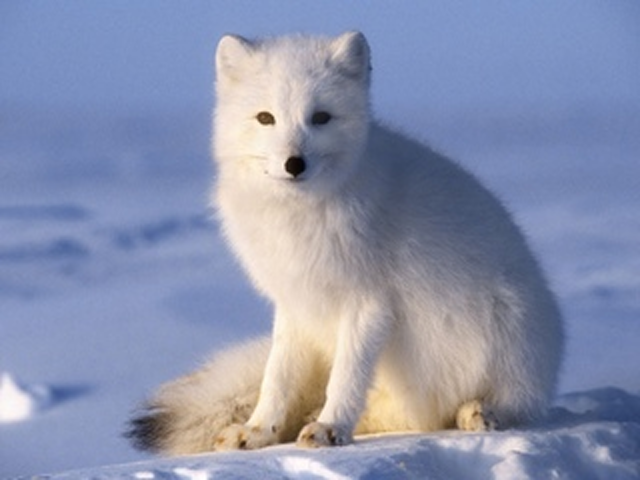

Бикубическая интерполяция (INTER_CUBIC)


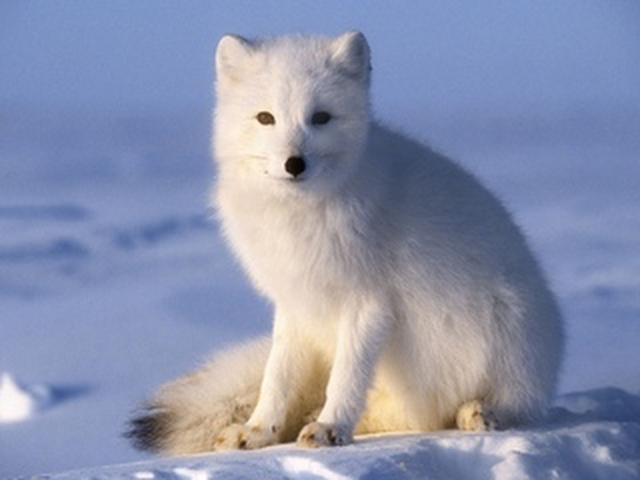

Интерполяция Ланцоша (INTER_LANCZOS4)

Размер исходного изображения: (240, 320, 3)
Размер увеличенных изображений: (480, 640, 3)


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab.patches import cv2_imshow

# Загрузка изображения с низким разрешением
low_res_image = cv2.imread('/content/low_arctic_fox.jpg')
low_res_image = cv2.cvtColor(low_res_image, cv2.COLOR_BGR2RGB)

# Определение коэффициента масштабирования
scale_factor = 2

# Применение различных методов интерполяции
nearest = cv2.resize(low_res_image, None, fx=scale_factor, fy=scale_factor, interpolation=cv2.INTER_NEAREST)
bilinear = cv2.resize(low_res_image, None, fx=scale_factor, fy=scale_factor, interpolation=cv2.INTER_LINEAR)
bicubic = cv2.resize(low_res_image, None, fx=scale_factor, fy=scale_factor, interpolation=cv2.INTER_CUBIC)
lanczos = cv2.resize(low_res_image, None, fx=scale_factor, fy=scale_factor, interpolation=cv2.INTER_LANCZOS4)

# Функция для отображения изображений с помощью cv2_imshow
def show_image(img, title):
    img_rgb = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)
    cv2_imshow(img_rgb)
    print(title)

# Отображение результатов
show_image(low_res_image, "Исходное изображение с низким разрешением")
show_image(nearest, "Метод ближайшего соседа (INTER_NEAREST)")
show_image(bilinear, "Билинейная интерполяция (INTER_LINEAR)")
show_image(bicubic, "Бикубическая интерполяция (INTER_CUBIC)")
show_image(lanczos, "Интерполяция Ланцоша (INTER_LANCZOS4)")

# Вывод размеров изображений
print(f"\nРазмер исходного изображения: {low_res_image.shape}")
print(f"Размер увеличенных изображений: {nearest.shape}")

Рассмотрим результаты более детально на примере фрагмента:

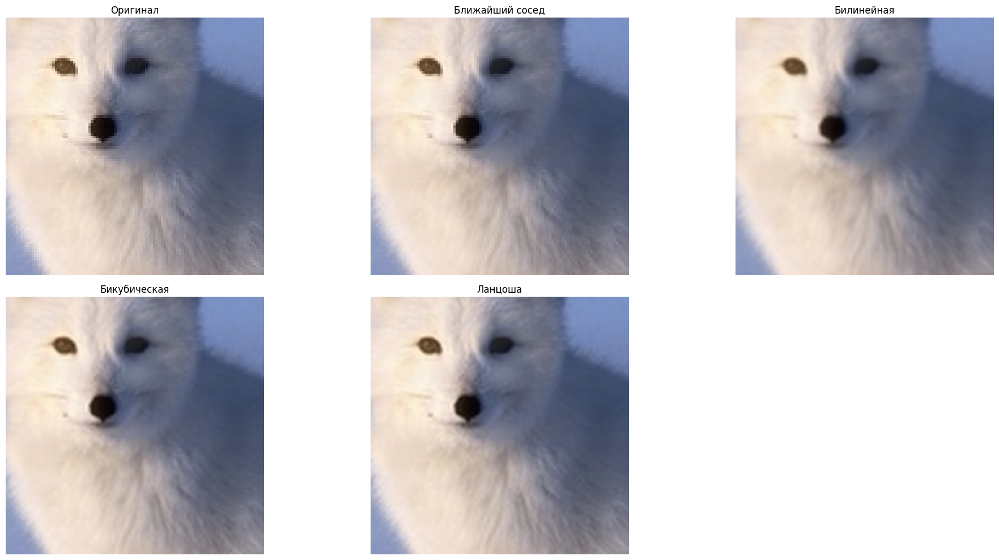

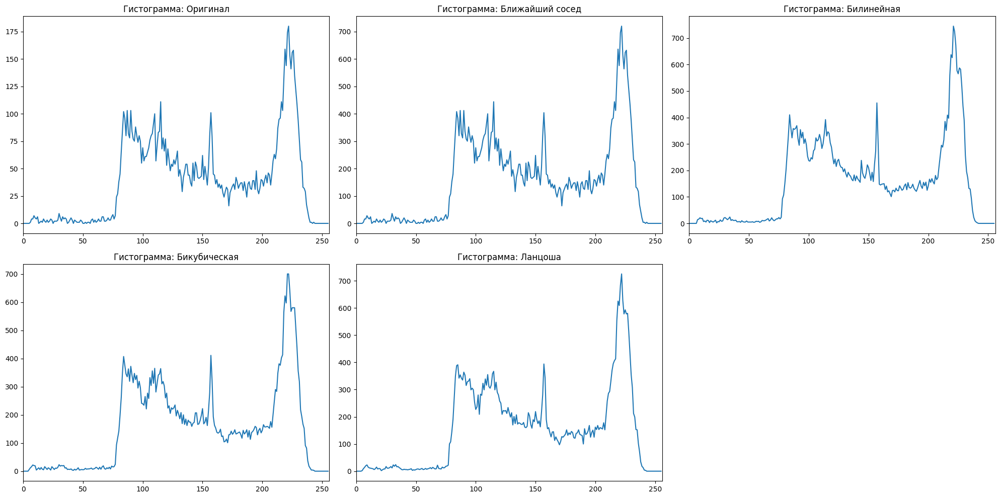

In [ ]:
import matplotlib.pyplot as plt
import cv2

# Предварительные вычисления относительных координат области обрезки
crop_size = 100
height, width = low_res_image.shape[:2]
rel_start_y = (height // 6) / height
rel_start_x = ((width - crop_size) // 2) / width
rel_crop_size_y = crop_size / height
rel_crop_size_x = crop_size / width

images = [low_res_image, nearest, bilinear, bicubic, lanczos]
titles = ['Оригинал', 'Ближайший сосед', 'Билинейная', 'Бикубическая', 'Ланцоша']

def get_crop(img):
    h, w = img.shape[:2]
    sy = int(rel_start_y * h)
    sx = int(rel_start_x * w)
    csy = int(rel_crop_size_y * h)
    csx = int(rel_crop_size_x * w)
    sy = min(sy, h - csy)
    sx = min(sx, w - csx)
    return img[sy:sy + csy, sx:sx + csx]

# Сравнение результатов интерполяции
plt.figure(figsize=(20, 10))
for i, (img, title) in enumerate(zip(images, titles), 1):
    plt.subplot(2, 3, i)
    crop = get_crop(img)
    plt.imshow(crop, cmap='gray')
    plt.title(title)
    plt.axis('off')
plt.tight_layout()
plt.show()

# Сравнение гистограмм
plt.figure(figsize=(20, 10))
for i, (img, title) in enumerate(zip(images, titles), 1):
    plt.subplot(2, 3, i)
    crop = get_crop(img)
    if len(crop.shape) == 3:
        crop_gray = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)
    else:
        crop_gray = crop
    hist = cv2.calcHist([crop_gray], [0], None, [256], [0, 256])
    plt.plot(hist)
    plt.title(f'Гистограмма: {title}')
    plt.xlim([0, 256])
plt.tight_layout()
plt.show()

## **3. Изменение яркости и контраста изображений**

Изменение яркости и контраста является важной задачей в обработке изображений. ркость определяет общую светлоту или темноту изображения, а контраст харатеризует степень различия между светлыми и темными участками изображения.

#### **Определения:**

- **Яркость** — это параметр, влияющий на общее освещение изображения. Изменение яркости приводит к тому, что все пиксели становятся светлее или темнее на одинаковую величину. Это смещает гистограмму яркости изображения вправо (увеличение яркости) или влево (уменьшение яркости).

- **Контраст** — это параметр, определяющий разницу в яркости между самыми светлыми и самыми темными частями изображения. Повышение контраста увеличивает эту разницу, делая светлые области еще светлее, а темные — еще темнее. Уменьшение контраста снижает разницу, делая изображение более однородным.

### **3.1. Арифметические операции с изображениями**

Изменение яркости и контраста можно реализовать с помощью простых арифметических операций над значениями пикселей:

- **Изменение яркости:**

Добавление или вычитание постоянного значения ко всем пикселям изображения.

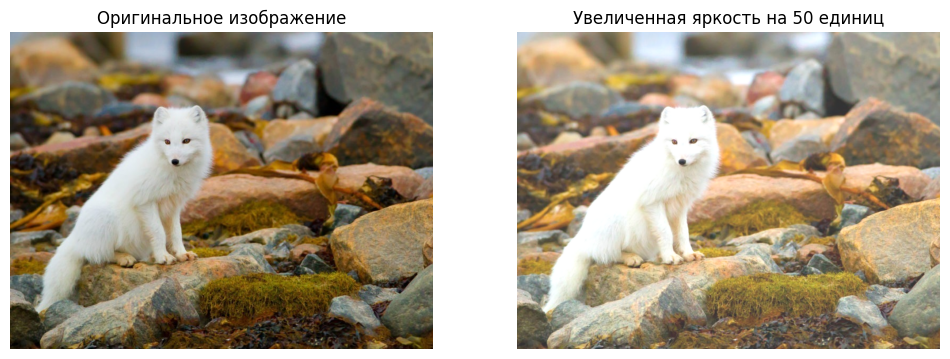

In [ ]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

# Загрузка изображения
image = cv2.imread('/content/arctic_fox.jpg')
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Преобразование типа данных к более высокоточному, чтобы избежать переполнения
image_int = image.astype(np.int16)

# Увеличение яркости на 50 единиц
brighter_image = image_int + 50

# Обработка переполнения и приведение типа данных обратно к uint8
brighter_image = np.clip(brighter_image, 0, 255).astype(np.uint8)

# Отображение результатов
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title('Оригинальное изображение')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(brighter_image)
plt.title('Увеличенная яркость на 50 единиц')
plt.axis('off')

plt.show()

При этом важно следить за переполнением диапазона значений пикселей (0-255 для 8-битных изображений).

- **Изменение контраста:**

Реализуем линейную коррекцию контраста с сохранением средней яркости изображения.

Данный алгоритм эффективно увеличивает или уменьшает контраст изображения, сохраняя при этом его общую яркость неизменной.

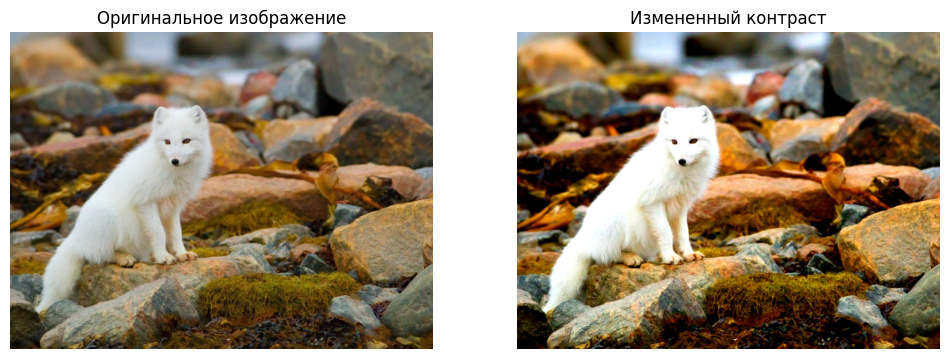

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Загрузка цветного изображения
image = cv2.imread('/content/arctic_fox.jpg')

# Вычисление средней яркости по всем каналам
mean = np.mean(image)

# Настройка параметра контраста
alpha = 1.5  # коэффициент контраста

# Изменение контраста с сохранением яркости
adjusted = alpha * (image - mean) + mean
adjusted = np.clip(adjusted, 0, 255).astype(np.uint8)

# Конвертация изображений из BGR в RGB для правильного отображения в matplotlib
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
adjusted_rgb = cv2.cvtColor(adjusted, cv2.COLOR_BGR2RGB)

# Отображение оригинального и обработанного изображений рядом
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title('Оригинальное изображение')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(adjusted_rgb)
plt.title('Измененный контраст')
plt.axis('off')

plt.show()

### **3.2. Использование метода cv2.convertScaleAbs() для настройки яркости и контраста**



Метод `cv2.convertScaleAbs()` из библиотеки OpenCV позволяет эффективно изменять яркость и контраст изображения, корректно обрабатывая переполнение и приводя результат к типу данных `uint8`.

**Синтаксис:**

```python
dst = cv2.convertScaleAbs(src, alpha=alpha, beta=beta)
```

- **`src`**: исходное изображение.
- **`alpha`**: коэффициент контраста (по умолчанию 1.0).
- **`beta`**: смещение яркости (по умолчанию 0).








#### Пример 1: Увеличение яркости

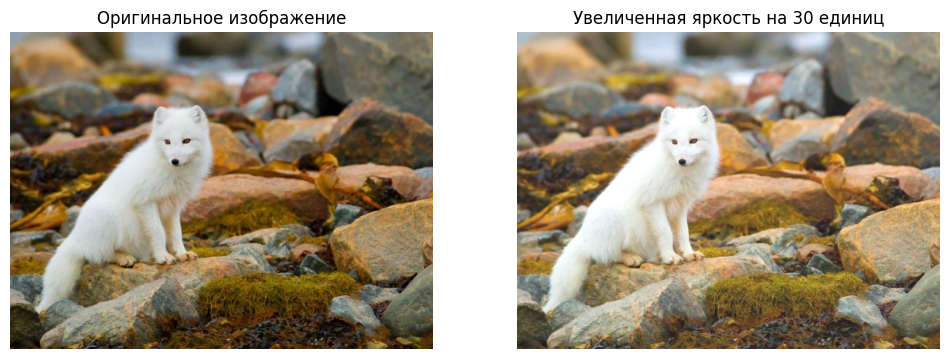

In [ ]:
# Увеличение яркости на 30 единиц
bright_image = cv2.convertScaleAbs(image, beta=30)

# Отображение оригинального и обработанного изображений
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title('Оригинальное изображение')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(bright_image)
plt.imshow(cv2.cvtColor(bright_image, cv2.COLOR_BGR2RGB))
plt.title('Увеличенная яркость на 30 единиц')
plt.axis('off')

plt.show()

**Результат:** все пиксели изображения станут светлее на 30 единиц, контраст останется прежним.

#### Пример 2: Уменьшение контраста

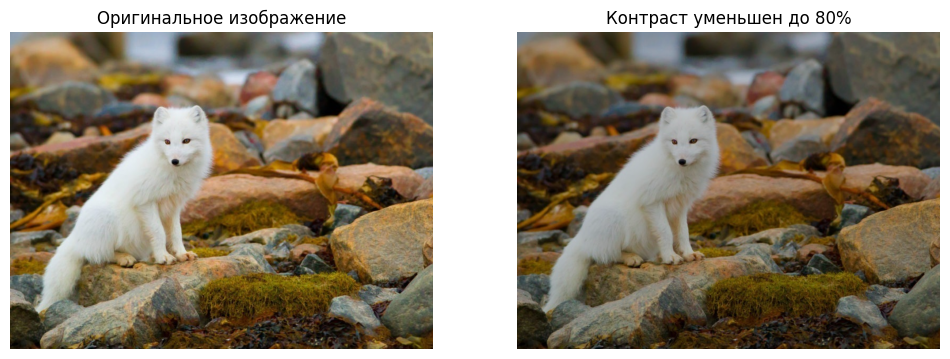

In [ ]:
# Уменьшение контраста до 80% от исходного
low_contrast_image = cv2.convertScaleAbs(image, alpha=0.8)

# Отображение изображений
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title('Оригинальное изображение')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(low_contrast_image, cv2.COLOR_BGR2RGB))
plt.title('Контраст уменьшен до 80%')
plt.axis('off')

plt.show()

**Результат:** различия между светлыми и темными областями уменьшатся, изображение станет более однородным.

#### Пример 3: Инвертирование изображения

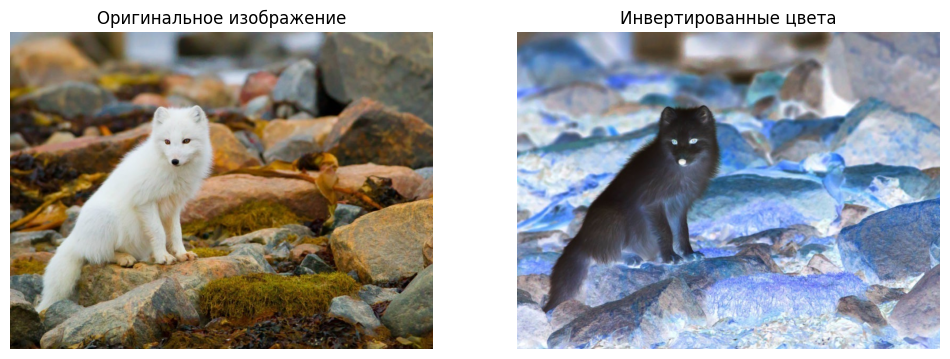

In [ ]:
# Инвертирование цветов изображения
inverted_image = cv2.convertScaleAbs(image, alpha=-1, beta=255)

# Отображение изображений
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title('Оригинальное изображение')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(inverted_image, cv2.COLOR_BGR2RGB))
plt.title('Инвертированные цвета')
plt.axis('off')

plt.show()

**Результат:** цвета изображения будут инвертированы, превращая светлые области в темные и наоборот.

#### Пример 4: Комбинированное изменение яркости и контраста

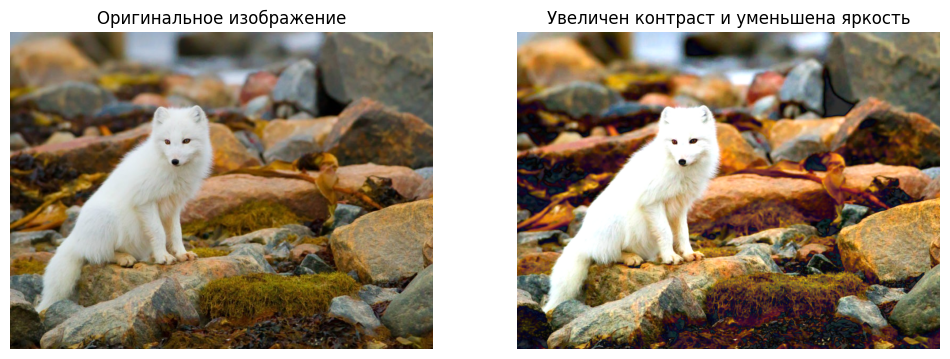

In [ ]:
# Повышение контраста и уменьшение яркости
adjusted_image = cv2.convertScaleAbs(image, alpha=1.5, beta=-50)

# Отображение изображений
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title('Оригинальное изображение')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(adjusted_image, cv2.COLOR_BGR2RGB))
plt.title('Увеличен контраст и уменьшена яркость')
plt.axis('off')

plt.show()



**Результат:** контраст увеличится на 50%, изображения станет более насыщенным, при этом общая яркость снизится, делая темные области еще темнее.

